# Evaluación 3 – Optimización y Auditoría de un Pipeline Integrado de Deep Learning
**Clasificación de 6 letras de la lengua de señas americana (Sign Language MNIST): MLP vs CNN**

**Asignatura:** TLY1102
**Docente:** Jazna Meza Hidalgo
**Grupo:** 5
**Integrantes:** Nicolas Fernandez Vera, Victor Gutierrez, Bastian Gutierrez
**Fecha:** Noviembre de 2026

---

## Descripción

Este notebook continúa las Actividades 3.4 (Pipeline Integrado) y 3.5 (Refinamiento Técnico). Se reutiliza la estructura modular de funciones vista en clase (cargar → preprocesar → construir → compilar → entrenar → evaluar) y se extiende con regularización, auditoría (métricas, matrices de confusión, sesgos), IA Explicable (Grad-CAM) y optimización de hiperparámetros con *grid search* para **comparar objetivamente una MLP optimizada y una CNN optimizada**.

**Protocolo de datos y entrenamiento:**
* Se usa el CSV de entrenamiento (`sign_mnist_train.csv`), dividido **80 % entrenamiento / 20 % validación por familias de imágenes**: todas las variaciones de una misma foto original quedan del mismo lado (sección 3).
* En la etapa de entrenamiento, **cada modelo (MLP y CNN) se entrena una sola vez**.
* La evaluación, la auditoría y la comparación se hacen con el **conjunto de validación**.
* La optimización de hiperparámetros (*grid search*) es la última etapa del pipeline.

## Requisitos de Software

Se usan las versiones preinstaladas en Google Colab de: `numpy`, `pandas`, `matplotlib`, `scipy`, `scikit-learn` y `tensorflow` (Keras). Se recomienda un entorno con GPU (*Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU*). Antes de ejecutar, subir `Sign Language MNIST.zip` al panel de archivos de Colab.


## Índice

1. Introducción
2. Carga de datos y análisis exploratorio
3. Preprocesamiento
4. Definición de los modelos (MLP y CNN)
5. Entrenamiento
6. Regularización
7. Evaluación de los modelos
8. Auditoría: métricas, matrices de confusión, sesgos y XAI
9. Optimización de hiperparámetros
10. Comparación MLP vs CNN
11. Conclusiones
12. Referencias

# 1. Introducción

## 1.1 Descripción del problema
Se debe resolver un problema de **clasificación multiclase de imágenes**: dada una imagen en escala de grises de 28×28 píxeles de una mano, el modelo debe identificar qué letra de la lengua de señas americana (ASL) representa, entre **6 letras: A, C, F, K, O e Y**. El conjunto de datos es **Sign Language MNIST**, entregado por la docente:

| Característica | Detalle |
|---|---|
| Imágenes | 28×28 píxeles, escala de grises (valores 0–255) |
| Clases usadas | **6 letras: A, C, F, K, O, Y** (etiquetas originales 0, 2, 5, 10, 14 y 24). El dataset completo tiene 24 letras; J y Z no están porque requieren movimiento |
| Datos usados | 6.902 imágenes de las 6 letras (de 27.455 en `sign_mnist_train.csv`), divididas 80/20 por familias: **5.640 para entrenar y 1.262 para validar** (82/18: al separar familias completas la proporción no es exacta) |
| Formato | Una fila por imagen: columna `label` + 784 columnas `pixel1…pixel784` |

## 1.2 Objetivo
Optimizar y auditar una solución de Deep Learning, comparando una **MLP** (Perceptrón Multicapa) y una **CNN** (Red Convolucional) bajo condiciones idénticas, para recomendar con evidencia experimental cuál es la mejor solución al problema. Se trabajan los dos indicadores de logro de la evaluación:

* **IL 3.1:** preprocesamiento y regularización integrados en un pipeline completo de entrenamiento, evaluación y optimización.
* **IL 3.2:** implicancias éticas del uso de datos: detección de sesgos, auditoría del modelo y uso de IA Explicable.

## 1.3 Arquitectura del Pipeline Integrado
El pipeline sigue las nueve etapas pedidas, en el mismo orden que las secciones del notebook:

| Etapa | Sección | Qué hace | Datos que usa |
|---|---|---|---|
| 1. Carga de datos | 2 | Descomprime, lee el CSV y conserva las 6 letras | CSV de entrenamiento |
| 2. Análisis exploratorio | 2 | Nulos, rango, balance de clases, ejemplos | CSV de entrenamiento |
| 3. Preprocesamiento | 3 | Normaliza, reestructura y divide 80/20 por familias | CSV de entrenamiento |
| 4. Construcción del modelo | 4 | MLP y CNN desde un mismo diccionario de configuración | — |
| 5. Entrenamiento | 5 | **Una sola vez por modelo** | 80 % entrenamiento + 20 % validación (curvas y Early Stopping) |
| 6. Regularización | 6 | Técnicas integradas en el entrenamiento y su análisis | Curvas de la sección 5 |
| 7. Evaluación | 7 | Cinco métricas y brecha entrenamiento–validación | Validación |
| 8. Auditoría | 8 | Matrices de confusión, curvas, sesgos y Grad-CAM | Validación |
| 9. Optimización | 9 | *Grid search* de hiperparámetros | Entrenamiento + validación |

Después del pipeline, la sección 10 compara la MLP y la CNN optimizadas y la 11 presenta las conclusiones.

## 1.4 Justificación de la estructura
* **Modularidad:** cada etapa es una función con una sola responsabilidad, lo que permite cambiarla sin romper las demás.
* **Reutilización sin duplicar código:** MLP y CNN pasan por *exactamente las mismas* funciones de entrenamiento, evaluación, auditoría y optimización; solo cambia el constructor del modelo.
* **Comparabilidad:** ambos modelos se describen con un diccionario de configuración (`cfg`) y comparten datos, partición, semilla, optimizador, tamaño de lote, épocas máximas y métricas.
* **Trazabilidad:** el registro `MODELOS` guarda el modelo de cada tipo entrenado en la sección 5 y el *grid search* reutiliza esa misma configuración en vez de reentrenarla.
* **Sin fuga de información (*data leakage*):** la partición por familias garantiza que ninguna foto original tenga variaciones en entrenamiento y validación a la vez (sección 3).

In [ ]:
import os, glob, json, time, zipfile, random, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks
tf.get_logger().setLevel("ERROR")   # oculta avisos internos de TensorFlow

from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_fscore_support)

# ---- Constantes globales del experimento (iguales para MLP y CNN) ----
SEMILLA = 42          # reproducibilidad
TAM_VAL = 0.2         # partición 80 % entrenamiento / 20 % validación
UMBRAL_FAMILIA = 0.10 # distancia de correlación máxima para considerar dos imágenes de la misma foto original
EPOCAS = 15           # máximo de épocas de cada entrenamiento
PACIENCIA = 3         # paciencia de Early Stopping (solo CNN)
BATCH = 128           # tamaño de lote, igual para ambos modelos
UMBRAL_CONFIANZA = 0.9   # umbral usado en la auditoría para proponer revisión humana
TIPOS = ['MLP', 'CNN']
CLASES_ELEGIDAS = [0, 2, 5, 10, 14, 24]   # etiquetas originales de las letras A, C, F, K, O, Y

# ---- Arquitecturas FIJAS ----
MLP_OCULTAS = [128, 64]   # Dense 128 ReLU -> Dense 64 ReLU (misma arquitectura de la E1)
CNN_FILTROS = [16, 32]    # dos bloques Conv2D 3x3 (stride 1, padding 'valid') + MaxPooling2D 2x2
CNN_DENSA = 64            # Dense 64 ReLU después del Flatten
RUTA_ZIP = '/content/Sign Language MNIST.zip'

def fijar_semillas():
    """Establece las semillas aleatorias para garantizar reproducibilidad."""
    random.seed(SEMILLA)
    np.random.seed(SEMILLA)
    tf.random.set_seed(SEMILLA)

# 2. Carga de datos y análisis exploratorio

**Etapas 1 y 2 del pipeline.** La carga se separa en tres funciones: una descomprime el archivo, otra lee el CSV de entrenamiento y otra conserva solo las 6 letras del proyecto. El análisis exploratorio (EDA) busca responder, antes de modelar: ¿hay valores nulos o fuera de rango?, ¿están balanceadas las clases?, ¿hay imágenes repetidas? y ¿cómo se ven las imágenes?

Imágenes: 6,902
Columnas: 1 etiqueta + 784 píxeles (imágenes de 28x28)
Valores nulos: 0
Rango de píxeles: [0, 255] | media = 157.9 | desv. estándar = 50.1
Clases: 6 | etiquetas originales [0, 2, 5, 10, 14, 24] -> letras A, C, F, K, O, Y
Imágenes por letra: A: 1126, C: 1144, F: 1204, K: 1114, O: 1196, Y: 1118
Razón entre la letra más y menos frecuente: 1.08
Imágenes duplicadas exactas: 0


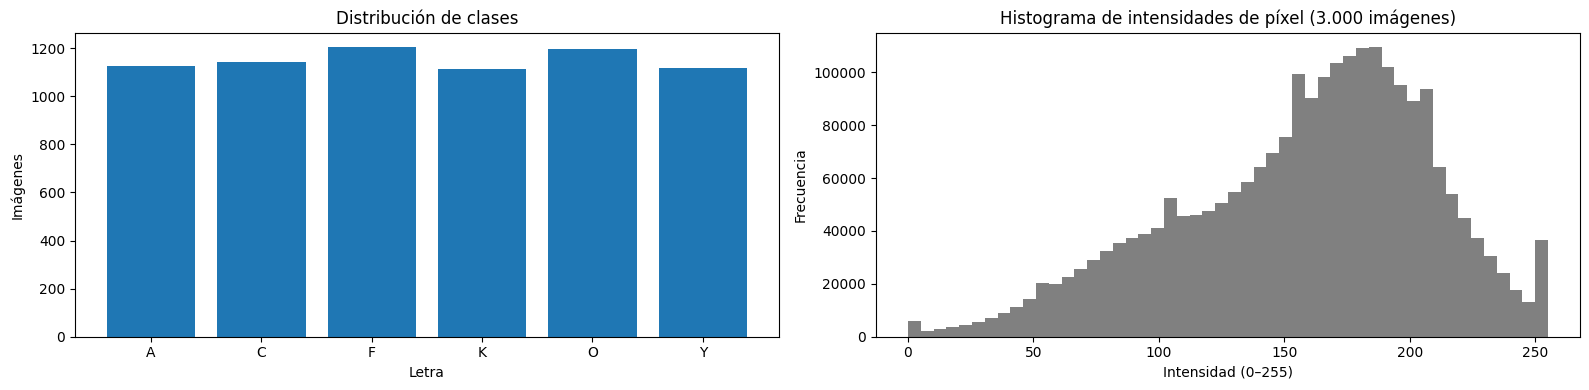

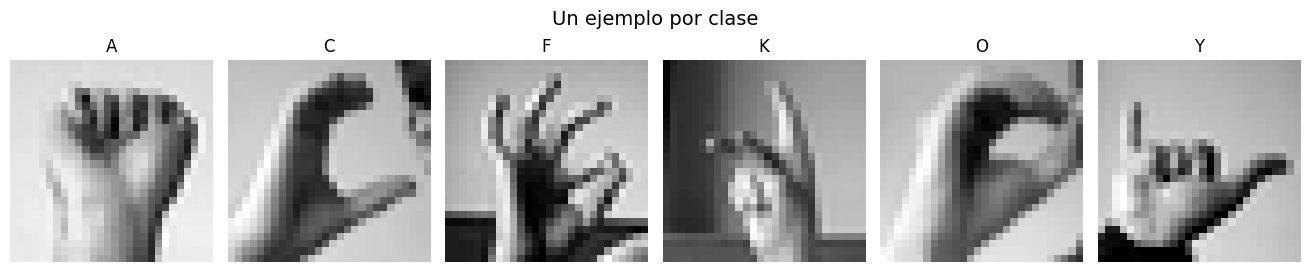

In [ ]:
def preparar_archivos(ruta_zip: str, destino: str = "/content/datos") -> str:
    """
    Descomprime el zip del dataset (si aún no está descomprimido). Si la ruta ya es una
    carpeta con los CSV, se usa directamente. Si el zip no está en 'ruta_zip', se busca en
    /content un zip cuyo nombre contenga "Sign Language MNIST" (con espacios o guiones bajos).

    Args:
        ruta_zip: ruta del archivo Sign Language MNIST.zip (o de la carpeta ya extraída).
        destino: carpeta donde se extraen los archivos.
    Returns:
        Ruta de la carpeta con los archivos extraídos.
    """
    if os.path.isdir(ruta_zip):
        return ruta_zip
    if not os.path.exists(ruta_zip):
        candidatos = glob.glob("/content/*ign*anguage*MNIST*.zip")
        if not candidatos:
            raise FileNotFoundError(f"No se encontró {ruta_zip}. Sube el zip al panel de archivos de Colab "
                                    "o corrige la variable RUTA_ZIP.")
        ruta_zip = candidatos[0]
    if not os.path.isdir(destino):
        with zipfile.ZipFile(ruta_zip) as z:
            z.extractall(destino)
    return destino


def cargar_datos(directorio: str) -> pd.DataFrame:
    """
    Carga el CSV de entrenamiento de Sign Language MNIST.

    Returns:
        DataFrame con la columna 'label' y 784 columnas de píxeles.
    """
    encontrados = sorted(glob.glob(os.path.join(directorio, "**", "sign_mnist_train.csv"), recursive=True))
    if not encontrados:
        raise FileNotFoundError(f"No se encontró sign_mnist_train.csv dentro de {directorio}")
    return pd.read_csv(encontrados[0])


def filtrar_clases(df: pd.DataFrame, clases: list) -> pd.DataFrame:
    """Conserva solo las imágenes cuya etiqueta original está en 'clases'."""
    return df[df["label"].isin(clases)].reset_index(drop=True)


def analisis_exploratorio(df: pd.DataFrame) -> None:
    """
    Resume el dataset (tamaño, nulos, rango, clases, duplicados) y grafica la distribución
    de clases, el histograma de intensidades y un ejemplo por clase.
    """
    pix = df.drop(columns="label").values
    clases = sorted(df["label"].unique())
    letras = [chr(65 + int(c)) for c in clases]
    ct = df["label"].value_counts().sort_index()

    print(f"Imágenes: {len(df):,}")
    print(f"Columnas: 1 etiqueta + {df.shape[1] - 1} píxeles (imágenes de 28x28)")
    print(f"Valores nulos: {int(df.isna().sum().sum())}")
    print(f"Rango de píxeles: [{pix.min()}, {pix.max()}] | media = {pix.mean():.1f} | desv. estándar = {pix.std():.1f}")
    print(f"Clases: {len(clases)} | etiquetas originales {[int(c) for c in clases]} -> letras {', '.join(letras)}")
    print("Imágenes por letra: " + ", ".join(f"{l}: {n}" for l, n in zip(letras, ct.values)))
    print(f"Razón entre la letra más y menos frecuente: {ct.max() / ct.min():.2f}")
    print(f"Imágenes duplicadas exactas: {int(df.duplicated().sum())}")

    fig, axes = plt.subplots(1, 2, figsize=(16, 4))
    x = np.arange(len(letras))
    axes[0].bar(x, ct.values, color="tab:blue")
    axes[0].set_xticks(x); axes[0].set_xticklabels(letras)
    axes[0].set_title("Distribución de clases"); axes[0].set_xlabel("Letra"); axes[0].set_ylabel("Imágenes")
    axes[1].hist(pix[:3000].ravel(), bins=50, color="gray")
    axes[1].set_title("Histograma de intensidades de píxel (3.000 imágenes)")
    axes[1].set_xlabel("Intensidad (0–255)"); axes[1].set_ylabel("Frecuencia")
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1, len(clases), figsize=(2.2 * len(clases), 2.8))
    for ax, c in zip(np.atleast_1d(axes), clases):
        fila = df[df["label"] == c].iloc[0, 1:].values.reshape(28, 28)
        ax.imshow(fila, cmap="gray"); ax.set_title(chr(65 + int(c))); ax.axis("off")
    plt.suptitle("Un ejemplo por clase", fontsize=14)
    plt.tight_layout(); plt.show()


directorio = preparar_archivos(RUTA_ZIP)
df = filtrar_clases(cargar_datos(directorio), CLASES_ELEGIDAS)
analisis_exploratorio(df)

### Hallazgos del análisis exploratorio
* El dataset **no tiene valores nulos** y los píxeles están en el rango esperado 0–255, por lo que no se requiere imputación; basta con escalar.
* Se conservan **6 clases** (A, C, F, K, O, Y). Sus etiquetas originales (0, 2, 5, 10, 14, 24) no son consecutivas, por lo que hay que **reasignarlas a 0–5** para que la capa de salida de 6 neuronas y la pérdida `sparse_categorical_crossentropy` funcionen correctamente.
* Las clases están **balanceadas** (entre 1.114 y 1.204 imágenes por letra; razón 1,08). Igual se usan métricas **macro** y por letra en la auditoría.
* No hay duplicados exactos, pero el dataset se generó creando más de 50 variaciones (recorte, brillo, rotación leve, pixelado) de un número reducido de fotos originales. Por eso hay muchas **casi-copias**, lo que condiciona la partición (sección 3).
* Las 6 letras tienen formas bastante distintas: puño cerrado (A), mano curva (C), círculo con pulgar e índice y tres dedos extendidos (F), dos dedos hacia arriba (K), círculo con todos los dedos (O), pulgar y meñique extendidos (Y). Los pares más parecidos son C/O (mano curva), F/O (círculo con los dedos) y K/Y (dedos extendidos).

# 3. Preprocesamiento

**Etapa 3 del pipeline.** Transformaciones aplicadas y su justificación:

| Paso | Qué se hace | Por qué |
|---|---|---|
| Normalización | Dividir los píxeles por 255 → rango [0, 1] | Entradas en escala pequeña estabilizan el descenso del gradiente y aceleran la convergencia |
| Reestructuración | Cada fila de 784 valores → imagen `(28, 28, 1)` | La CNN necesita la estructura espacial; la MLP la aplana internamente con `Flatten`. Ambas reciben así los mismos datos |
| Selección de clases | Se conservan solo las etiquetas 0, 2, 5, 10, 14 y 24 (A, C, F, K, O, Y) | Subconjunto de letras definido para el proyecto |
| Reasignación de etiquetas | 0, 2, 5, 10, 14, 24 → 0–5 | La capa de salida tiene exactamente una neurona por letra |
| Familias de imágenes | Dentro de cada letra, las imágenes casi iguales se agrupan en una "familia" (clustering jerárquico con distancia de correlación) | Cada familia corresponde a las variaciones de una misma foto original |
| Partición 80/20 por familias | `StratifiedGroupKFold` (5 pliegues, semilla 42): un pliegue = validación, el resto = entrenamiento | Ninguna familia queda repartida entre entrenamiento y validación, y la proporción de letras se mantiene |

**¿Por qué por familias y no al azar?** Con una partición aleatoria, las variaciones de una misma foto quedan a ambos lados: el modelo valida con imágenes casi iguales a las que ya vio y la validación sale artificialmente alta (≈ 99 %). Separando por familias, la validación mide el desempeño con **fotos que el modelo no vio**.

**Cómo se forman las familias:** se usa la distancia de correlación (1 − correlación de Pearson entre los píxeles de dos imágenes), que no cambia con el brillo ni el contraste, y enlace promedio con umbral 0,10. No se calcula ningún parámetro del modelo a partir de los datos (la normalización es una división fija por 255).

In [ ]:
def a_tensores(df: pd.DataFrame, mapa: dict):
    """Normaliza a [0, 1], reestructura a (28, 28, 1) y reasigna las etiquetas de un DataFrame."""
    X = (df.drop(columns="label").values.astype("float32") / 255.0).reshape(-1, 28, 28, 1)
    y = df["label"].map(mapa).values.astype("int32")
    return X, y


def agrupar_familias(X: np.ndarray, y: np.ndarray, umbral: float = UMBRAL_FAMILIA) -> np.ndarray:
    """
    Agrupa en "familias" las imágenes casi iguales (variaciones de una misma foto original).

    Dentro de cada letra se aplica clustering jerárquico con enlace promedio y distancia de
    correlación (1 − correlación de Pearson entre píxeles, insensible a brillo y contraste).
    Las imágenes a menos de 'umbral' quedan en la misma familia.

    Returns:
        Vector con el número de familia de cada imagen.
    """
    grupos = np.empty(len(y), dtype=int)
    desfase = 0
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        Z = linkage(pdist(X[idx].reshape(len(idx), -1), "correlation"), method="average")
        etiquetas = fcluster(Z, umbral, criterion="distance")
        grupos[idx] = etiquetas + desfase
        desfase += etiquetas.max()
    return grupos


def preprocesar_datos(df: pd.DataFrame, tam_val: float = TAM_VAL, semilla: int = SEMILLA) -> dict:
    """
    Convierte el DataFrame en tensores y lo divide 80/20 por familias.

    Returns:
        Diccionario con X_train, y_train, X_val, y_val, las familias de cada imagen
        (g_train, g_val) y 'letras'.
    """
    clases = sorted(df["label"].unique())
    mapa = {c: i for i, c in enumerate(clases)}
    letras = [chr(65 + int(c)) for c in clases]
    X, y = a_tensores(df, mapa)
    grupos = agrupar_familias(X, y)
    sgkf = StratifiedGroupKFold(n_splits=round(1 / tam_val), shuffle=True, random_state=semilla)
    i_train, i_val = next(sgkf.split(X.reshape(len(X), -1), y, groups=grupos))

    datos = dict(X_train=X[i_train], y_train=y[i_train], X_val=X[i_val], y_val=y[i_val],
                 g_train=grupos[i_train], g_val=grupos[i_val], letras=letras)
    tam = np.bincount(grupos)[1:]; tam = tam[tam > 0]
    print(f"Familias encontradas: {len(tam)} | imágenes por familia: mediana {int(np.median(tam))}, máximo {tam.max()}")
    for k in ["train", "val"]:
        Xk, yk, gk = datos[f"X_{k}"], datos[f"y_{k}"], datos[f"g_{k}"]
        print(f"X_{k:<5}: {Xk.shape} ({100 * len(yk) / len(y):.1f} %) | familias: {len(np.unique(gk))} | por letra: "
              + ", ".join(f"{l}={n}" for l, n in zip(letras, np.bincount(yk, minlength=len(letras)))))
    print(f"Familias compartidas entre entrenamiento y validación: {len(set(datos['g_train']) & set(datos['g_val']))}")
    return datos


datos = preprocesar_datos(df)
N_CLASES = len(datos["letras"])

Familias encontradas: 253 | imágenes por familia: mediana 21, máximo 84
X_train: (5640, 28, 28, 1) (81.7 %) | familias: 203 | por letra: A=877, C=895, F=1018, K=826, O=1052, Y=972
X_val  : (1262, 28, 28, 1) (18.3 %) | familias: 50 | por letra: A=249, C=249, F=186, K=288, O=144, Y=146
Familias compartidas entre entrenamiento y validación: 0


### Verificación de la partición
Para comprobar que la partición por familias funciona, se mide para cada imagen de validación la distancia (RMSE de píxeles en [0, 1]) a la imagen de entrenamiento más parecida, y se compara con lo que ocurriría con una partición aleatoria 80/20 del mismo CSV.

In [ ]:
def distancia_minima(A: np.ndarray, B: np.ndarray, bloque: int = 500) -> np.ndarray:
    """RMSE de píxeles entre cada imagen de A y su imagen más parecida en B."""
    A, B = A.reshape(len(A), -1), B.reshape(len(B), -1)
    b2 = (B ** 2).sum(1)
    salida = np.empty(len(A))
    for i in range(0, len(A), bloque):
        a = A[i:i + bloque]
        d2 = (a ** 2).sum(1)[:, None] + b2[None, :] - 2 * a @ B.T
        salida[i:i + bloque] = np.sqrt(np.maximum(d2.min(1), 0) / A.shape[1])
    return salida


def verificar_casi_copias(datos: dict, umbral: float = 0.05) -> None:
    """Compara las casi-copias en validación con partición por familias y con partición aleatoria."""
    X = np.concatenate([datos["X_train"], datos["X_val"]]); y = np.concatenate([datos["y_train"], datos["y_val"]])
    Xa_tr, Xa_val = train_test_split(X, test_size=TAM_VAL, stratify=y, random_state=SEMILLA)
    for nombre, Xv, Xt in [("Partición aleatoria (referencia)", Xa_val, Xa_tr),
                           ("Partición por familias (usada)", datos["X_val"], datos["X_train"])]:
        d = distancia_minima(Xv, Xt)
        print(f"{nombre:<33}: validación con casi-copia en entrenamiento (RMSE < {umbral}) = {100 * np.mean(d < umbral):5.1f} % "
              f"| RMSE mediano = {np.median(d):.3f}")


verificar_casi_copias(datos)

Partición aleatoria (referencia) : validación con casi-copia en entrenamiento (RMSE < 0.05) =  94.9 % | RMSE mediano = 0.017
Partición por familias (usada)   : validación con casi-copia en entrenamiento (RMSE < 0.05) =   0.7 % | RMSE mediano = 0.099


**Lectura:** con una partición aleatoria, el **94,9 %** de las imágenes de validación tendría una casi-copia en entrenamiento (RMSE mediano 0,017, unos 4 niveles de gris de diferencia), y la validación mediría la capacidad de reconocer fotos ya vistas. Con la partición por familias ese porcentaje cae a **0,7 %** (RMSE mediano 0,099): la validación mide el desempeño con fotos nuevas, y por eso es la base de la evaluación, la auditoría, la optimización y la comparación.

# 4. Definición de los modelos (MLP y CNN)

**Etapa 4 del pipeline.** Ambas redes se construyen con la API funcional de Keras a partir de un diccionario de configuración `cfg`. Con esto un mismo constructor permite activar o desactivar cada técnica de regularización sin duplicar código.

| Elemento | Decisión | Justificación |
|---|---|---|
| Activación de capas ocultas | **ReLU** | Barata de calcular y mitiga el desvanecimiento del gradiente |
| Inicialización de pesos | **He normal** en capas con ReLU | Mantiene la varianza de las activaciones con ReLU (visto en clase). La capa de salida usa la inicialización por defecto (Glorot) porque su activación es *softmax* |
| Capa de salida | **Dense(6) + softmax** | Clasificación multiclase: devuelve una probabilidad por letra |
| Pérdida | `sparse_categorical_crossentropy` | Etiquetas enteras (0–5) y salida softmax |
| Optimizador | **Adam** | Tasa de aprendizaje adaptativa; es el optimizador estándar visto en clase |
| Métrica de entrenamiento | `accuracy` | Seguimiento básico; las demás métricas se calculan en la evaluación y la auditoría |

**MLP (arquitectura de la E1, fija):** `Flatten` → `Dense(128, ReLU)` → `Dense(64, ReLU)` → `Dense(6, softmax)` (109.126 parámetros sin Batch Normalization).
`Flatten` **no borra valores**: los 784 píxeles de la imagen se conservan y solo se reordenan en un vector de 784 posiciones. Lo que la MLP no aprovecha es la *estructura* espacial: cada neurona densa se conecta con todos los píxeles por igual, sin saber cuáles son vecinos.

**CNN (arquitectura fija):** dos bloques convolucionales y una parte densa (56.454 parámetros sin Batch Normalization, casi la mitad que la MLP):
| Capa | Configuración | Salida |
|---|---|---|
| Conv2D + ReLU | 16 filtros 3×3, stride 1, padding `valid` | 26×26×16 |
| MaxPooling2D | ventana 2×2, stride 2×2 | 13×13×16 |
| Conv2D + ReLU | 32 filtros 3×3, stride 1, padding `valid` | 11×11×32 |
| MaxPooling2D | ventana 2×2, stride 2×2 | 5×5×32 |
| Flatten | — | 800 |
| Dense + ReLU | 64 neuronas | 64 |
| Dense + softmax | 6 neuronas (una por letra) | 6 |

Los filtros detectan patrones locales (bordes, contornos de dedos) con pesos compartidos en toda la imagen, y el *pooling* reduce el tamaño y aporta tolerancia a pequeños desplazamientos.

**El número de capas y de neuronas/filtros es fijo en ambos modelos.** Las técnicas de regularización solo se agregan alrededor de esas capas, sin cambiar sus tamaños: Batch Normalization y Dropout después de cada capa oculta, L2 sobre los pesos, Data Augmentation a la entrada y Early Stopping durante el entrenamiento (sección 6). La celda siguiente muestra la arquitectura base, sin regularización.

In [ ]:
def agregar_data_augmentation(x):
    """
    Agrega capas de aumento de datos (solo activas durante el entrenamiento).

    Se usan rotaciones, traslaciones y zoom pequeños. No se usan giros horizontales porque
    espejar una mano cambia el significado de la seña.
    """
    x = layers.RandomRotation(0.05, fill_mode="nearest", name="aug_rotacion")(x)
    x = layers.RandomTranslation(0.1, 0.1, fill_mode="nearest", name="aug_traslacion")(x)
    x = layers.RandomZoom(0.1, fill_mode="nearest", name="aug_zoom")(x)
    return x


def _regularizador_l2(l2: float):
    """Devuelve un regularizador L2 si el coeficiente es mayor que cero."""
    return regularizers.l2(l2) if l2 > 0 else None


def capa_densa(x, unidades: int, cfg: dict, nombre: str):
    """Bloque denso: Dense (He normal) -> [BatchNorm] -> ReLU -> [Dropout], según 'cfg'."""
    x = layers.Dense(unidades, use_bias=not cfg["bn"], kernel_initializer="he_normal",
                     kernel_regularizer=_regularizador_l2(cfg["l2"]), name=f"{nombre}_dense")(x)
    if cfg["bn"]:
        x = layers.BatchNormalization(name=f"{nombre}_bn")(x)
    x = layers.Activation("relu", name=f"{nombre}_relu")(x)
    if cfg["dropout"] > 0:
        x = layers.Dropout(cfg["dropout"], name=f"{nombre}_dropout")(x)
    return x


def construir_mlp(cfg: dict, input_shape=(28, 28, 1), n_clases: int = 6):
    """
    Construye la MLP fija: [Aug] -> Flatten -> Dense(128) -> Dense(64) -> Dense(n_clases, softmax).

    Args:
        cfg: configuración de regularización (bn, dropout, l2, aug).
    """
    entrada = keras.Input(shape=input_shape, name="entrada")
    x = agregar_data_augmentation(entrada) if cfg["aug"] else entrada
    x = layers.Flatten(name="aplanado")(x)
    for i, unidades in enumerate(MLP_OCULTAS):
        x = capa_densa(x, unidades, cfg, f"oculta_{i + 1}")
    salida = layers.Dense(n_clases, activation="softmax", name="salida")(x)
    return keras.Model(entrada, salida, name="MLP")


def construir_cnn(cfg: dict, input_shape=(28, 28, 1), n_clases: int = 6):
    """
    Construye la CNN fija: [Aug] -> (Conv2D 3x3 stride 1 'valid' -> [BatchNorm] -> ReLU -> MaxPool 2x2)
    con 16 y 32 filtros -> Flatten -> Dense(64) -> Dense(n_clases, softmax).

    Args:
        cfg: configuración de regularización (bn, dropout, l2, aug).
    """
    entrada = keras.Input(shape=input_shape, name="entrada")
    x = agregar_data_augmentation(entrada) if cfg["aug"] else entrada
    for i, filtros in enumerate(CNN_FILTROS):
        x = layers.Conv2D(filtros, 3, strides=1, padding="valid", use_bias=not cfg["bn"],
                          kernel_initializer="he_normal",
                          kernel_regularizer=_regularizador_l2(cfg["l2"]), name=f"conv_{i + 1}")(x)
        if cfg["bn"]:
            x = layers.BatchNormalization(name=f"conv_{i + 1}_bn")(x)
        x = layers.Activation("relu", name=f"conv_{i + 1}_relu")(x)
        x = layers.MaxPooling2D(pool_size=2, strides=2, name=f"pool_{i + 1}")(x)
    x = layers.Flatten(name="aplanado")(x)
    x = capa_densa(x, CNN_DENSA, cfg, "densa")
    salida = layers.Dense(n_clases, activation="softmax", name="salida")(x)
    return keras.Model(entrada, salida, name="CNN")


def construir_modelo(cfg: dict):
    """Selecciona el constructor según cfg['modelo'] ('MLP' o 'CNN')."""
    constructores = {"MLP": construir_mlp, "CNN": construir_cnn}
    return constructores[cfg["modelo"]](cfg, n_clases=N_CLASES)


# Arquitectura base (sin regularización), solo para mostrar las capas fijas. No se entrena.
SIN_REGULARIZACION = dict(dropout=0.0, l2=0.0, bn=False, aug=False)
for tipo in TIPOS:
    print(f"===== Arquitectura base: {tipo} =====")
    construir_modelo({"modelo": tipo, **SIN_REGULARIZACION}).summary()

===== Arquitectura base: MLP =====


Model: "MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ entrada (InputLayer)            │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aplanado (Flatten)              │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_1_dense (Dense)          │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_1_relu (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2_dense (Dense)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2_relu (Activation)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,126 (426.27 KB)

 Trainable params: 109,126 (426.27 KB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ entrada (InputLayer)            │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1_relu (Activation)        │ (None, 26, 26, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2_relu (Activation)        │ (None, 11, 11, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aplanado (Flatten)              │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa_dense (Dense)             │ (None, 64)             │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa_relu (Activation)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,454 (220.52 KB)

 Trainable params: 56,454 (220.52 KB)

 Non-trainable params: 0 (0.00 B)

# 5. Entrenamiento

**Etapa 5 del pipeline.** Cada modelo se entrena **una única vez**, bajo las mismas condiciones:

| Condición | Valor |
|---|---|
| Datos de entrenamiento | 80 % del CSV (familias de entrenamiento) |
| Datos de validación | 20 % del CSV (familias de validación): curvas y Early Stopping |
| Optimizador y pérdida | Adam + `sparse_categorical_crossentropy` |
| Épocas máximas | 15 (la MLP entrena siempre 15; la CNN usa Early Stopping) |
| Tamaño de lote | 128 en ambos modelos |
| Semilla | Se fija antes de construir cada modelo |

**Configuración de partida (`CFG`):** cada modelo se entrena con sus técnicas de regularización integradas (sección 6) y con hiperparámetros de partida tomados de la actividad 3.5: MLP con lr = 0,0001 y Dropout 0,3; CNN con lr = 0,001, Dropout 0,3 y L2 = 0,001. Estos valores se optimizan con *grid search* en la sección 9.

`entrenar` encapsula construir → compilar → entrenar y mide el **tiempo de entrenamiento**; `entrenar_una_vez` la usa y guarda el resultado en el registro `MODELOS`, de modo que si la celda se vuelve a ejecutar el modelo se reutiliza y no se entrena de nuevo.

> **Nota sobre las curvas:** durante `fit`, Keras mide el accuracy de entrenamiento con Dropout y Data Augmentation activos, por lo que la curva de entrenamiento puede quedar por debajo de la de validación. Por eso, en la sección 7 la brecha entrenamiento − validación se calcula reevaluando el modelo sobre el entrenamiento en **modo inferencia**.

In [ ]:
# ---- Configuración de partida de cada modelo: regularización (sección 6) + hiperparámetros iniciales ----
CFG = {
    "MLP": dict(modelo="MLP", lr=1e-4, batch_size=BATCH, epocas=EPOCAS,
                bn=True, dropout=0.3, l2=0.0, aug=False, es=False),
    "CNN": dict(modelo="CNN", lr=1e-3, batch_size=BATCH, epocas=EPOCAS,
                bn=True, dropout=0.3, l2=1e-3, aug=True, es=True),
}
display(pd.DataFrame(CFG).T.rename(columns={
    "modelo": "Modelo", "lr": "Tasa de aprendizaje", "batch_size": "Lote", "epocas": "Épocas máx.",
    "bn": "Batch Norm", "dropout": "Dropout", "l2": "L2", "aug": "Data Augmentation", "es": "Early Stopping"}))

,Modelo,Tasa de aprendizaje,Lote,Épocas máx.,Batch Norm,Dropout,L2,Data Augmentation,Early Stopping
MLP,MLP,0.0001,128,15,True,0.3,0.0,False,False
CNN,CNN,0.001,128,15,True,0.3,0.001,True,True


[MLP] entrenado una vez: 15 épocas ejecutadas | época elegida = 15 | 109,702 parámetros | 11 s
[CNN] entrenado una vez: 15 épocas ejecutadas | época elegida = 15 | 56,790 parámetros | 16 s


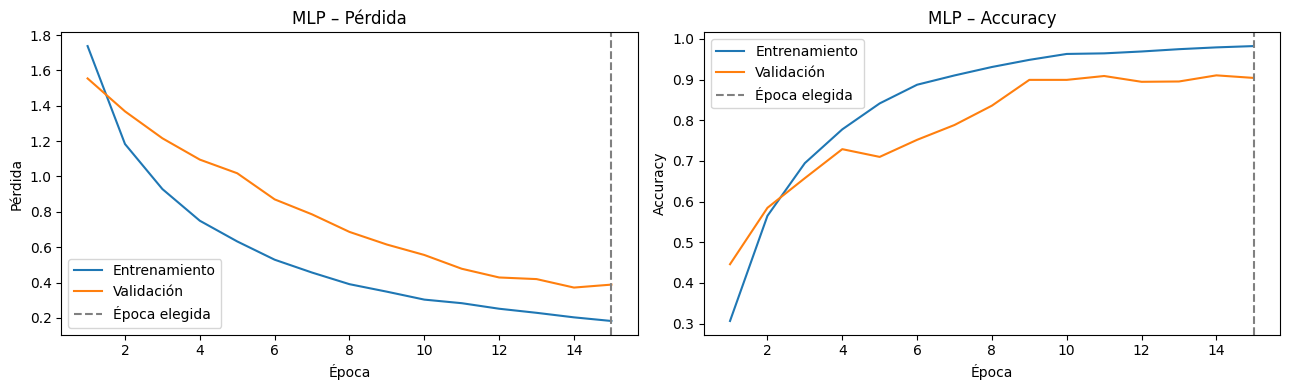

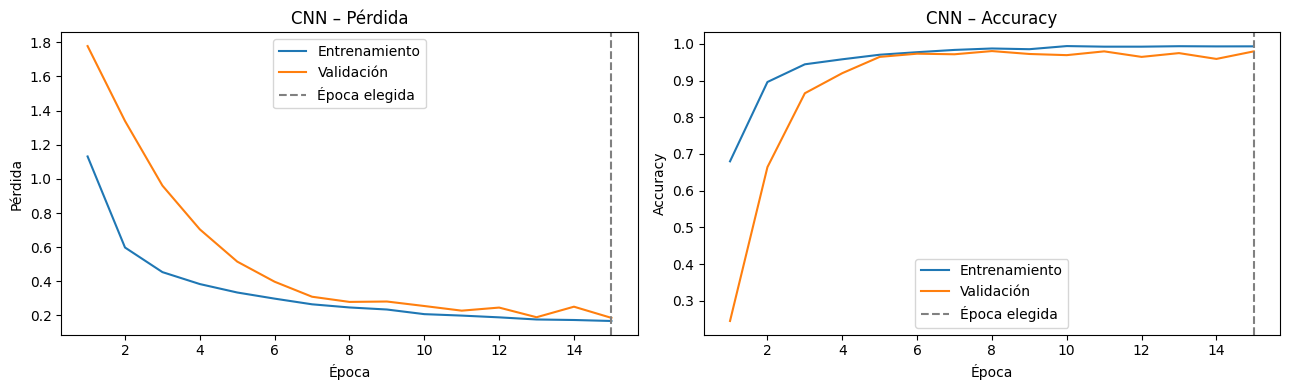

In [ ]:
def compilar_modelo(modelo, lr: float):
    """Compila el modelo con Adam, entropía cruzada categórica dispersa y accuracy."""
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return modelo


def entrenar(cfg: dict, datos: dict) -> dict:
    """
    Construye, compila y entrena el modelo de 'cfg' con el 80 % de entrenamiento, usando el 20 % de
    validación para las curvas y, si cfg['es'] es True, para Early Stopping (restaura los mejores pesos).

    Returns:
        Diccionario con cfg, modelo, historial, tiempo, épocas ejecutadas, época elegida y parámetros.
    """
    fijar_semillas()
    modelo = compilar_modelo(construir_modelo(cfg), cfg["lr"])
    cbs = []
    if cfg["es"]:
        cbs.append(callbacks.EarlyStopping(monitor="val_loss", patience=PACIENCIA,
                                           restore_best_weights=True))
    t0 = time.perf_counter()
    h = modelo.fit(datos["X_train"], datos["y_train"],
                   validation_data=(datos["X_val"], datos["y_val"]),
                   epochs=cfg["epocas"], batch_size=cfg["batch_size"],
                   callbacks=cbs, verbose=0)
    segundos = time.perf_counter() - t0
    hist = pd.DataFrame(h.history)
    idx = int(hist["val_loss"].idxmin()) if cfg["es"] else len(hist) - 1
    return dict(cfg=cfg, modelo=modelo, hist=hist, tiempo=segundos, epocas_ejecutadas=len(hist),
                epoca_elegida=idx + 1, val_loss=float(hist.loc[idx, "val_loss"]), params=modelo.count_params())


MODELOS = {}   # registro: el modelo entrenado en esta sección, uno por tipo ('MLP' y 'CNN')


def entrenar_una_vez(cfg: dict, datos: dict) -> dict:
    """Entrena UNA sola vez el modelo de cfg['modelo']; si ya está en MODELOS, lo reutiliza."""
    tipo = cfg["modelo"]
    if tipo in MODELOS:
        print(f"[{tipo}] ya está entrenado: se reutiliza (no se vuelve a entrenar).")
        return MODELOS[tipo]
    MODELOS[tipo] = r = entrenar(cfg, datos)
    print(f"[{tipo}] entrenado una vez: {r['epocas_ejecutadas']} épocas ejecutadas | época elegida = {r['epoca_elegida']} | "
          f"{r['params']:,} parámetros | {r['tiempo']:.0f} s")
    return r


def graficar_train_val(res: dict, titulo: str) -> None:
    """Curvas de aprendizaje (pérdida y accuracy) de entrenamiento vs validación."""
    h = res["hist"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, (m, nombre) in zip(axes, [("loss", "Pérdida"), ("accuracy", "Accuracy")]):
        ax.plot(h.index + 1, h[m], label="Entrenamiento")
        ax.plot(h.index + 1, h["val_" + m], label="Validación")
        ax.axvline(res["epoca_elegida"], color="gray", ls="--", label="Época elegida")
        ax.set_xlabel("Época"); ax.set_ylabel(nombre); ax.set_title(f"{titulo} – {nombre}"); ax.legend()
    plt.tight_layout(); plt.show()


# ---- ÚNICO entrenamiento de cada modelo ----
for tipo in TIPOS:
    entrenar_una_vez(CFG[tipo], datos)
for tipo in TIPOS:
    graficar_train_val(MODELOS[tipo], f"{tipo}")

### Lectura de las curvas
* **MLP:** la pérdida de entrenamiento baja durante las 15 épocas (≈ 0,18), mientras la de validación se estanca en ≈ 0,4 desde la época 12. El accuracy de entrenamiento llega a ≈ 98 % y el de validación se queda en ≈ 90 % desde la época 9. Es **sobreajuste**: la MLP memoriza las fotos de entrenamiento mejor de lo que generaliza a fotos nuevas.
* **CNN:** el accuracy de validación llega a ≈ 97 % desde la época 5 y queda cerca del de entrenamiento (≈ 99 %). La pérdida de validación sigue bajando hasta la época 15, por lo que Early Stopping no se activó y se usan los pesos de la última época. La distancia entre las curvas es mucho menor que en la MLP.
* En la CNN, la línea punteada marca la época que **Early Stopping** eligió (la de menor `val_loss`).

# 6. Regularización

**Etapa 6 del pipeline.** La regularización busca mejorar la generalización, es decir, el desempeño en datos no vistos. Se aplica el *panel de diagnóstico* visto en clase: cada técnica ataca un síntoma distinto.

| Síntoma | Técnica | Qué hace | Cómo se implementa aquí |
|---|---|---|---|
| Dependencia excesiva de neuronas específicas (alta varianza) | **Dropout** | Apaga neuronas al azar en cada paso de entrenamiento, forzando representaciones redundantes | `Dropout(0.3)` tras las capas densas |
| Entrenamiento excesivo (divergencia entre train y val) | **Early Stopping** | Detiene el entrenamiento cuando `val_loss` deja de mejorar y restaura los mejores pesos | `EarlyStopping(patience=3, restore_best_weights=True)` |
| Pesos excesivamente grandes | **Regularización L2** | Suma a la pérdida una penalización proporcional al cuadrado de los pesos | `kernel_regularizer=l2(1e-3)` |
| Distribución inestable de activaciones | **Batch Normalization** | Normaliza las activaciones de cada capa por lote; estabiliza y acelera el entrenamiento y regulariza levemente | `BatchNormalization` antes de la ReLU |
| Cantidad limitada de datos | **Data Augmentation** | Genera variaciones plausibles de cada imagen en cada época | Rotación de hasta ±18°, traslación y zoom de hasta ±10 %; sin espejo |
| Inicialización inadecuada | **Inicialización He** | Evita activaciones que se desvanecen o explotan con ReLU | Incluida en ambos modelos |

**Técnicas por modelo:**
| Técnica | MLP | CNN |
|---|---|---|
| Batch Normalization | ✔ | ✔ |
| Dropout | ✔ (0,3) | ✔ (0,3) |
| Regularización L2 | — | ✔ (1e-3) |
| Data Augmentation | — | ✔ |
| Early Stopping | — (entrena siempre 15 épocas) | ✔ |
| Inicialización He | ✔ | ✔ |

La MLP mantiene el esquema de la E1 y solo incorpora técnicas internas de la red (Batch Normalization y Dropout); la CNN usa las cinco técnicas. Todas van integradas en la configuración con la que se entrena cada modelo (`CFG`, sección 5).

### Cómo interpretar los resultados de regularización
* **Brecha** = accuracy de entrenamiento (en modo inferencia) − accuracy de validación (sección 7). Una brecha menor indica menos sobreajuste.
* **Val loss** es la métrica más sensible al sobreajuste: puede empeorar aunque el accuracy se mantenga, porque el modelo se vuelve "demasiado seguro" de sus errores.
* **Early Stopping** no cambia la arquitectura: elige el mejor momento del entrenamiento (línea punteada de las curvas).
* **Data Augmentation y Dropout** hacen que la curva de entrenamiento suba más lento y quede cerca o por debajo de la de validación; eso es esperable y no es una señal de mal ajuste.
* **Batch Normalization** se evalúa principalmente por velocidad y estabilidad de convergencia (primeras épocas de las curvas).

### Resultados del estudio de regularización (validación)
* **Curvas y brecha (secciones 5 y 7):** con la regularización de partida, la MLP termina con una brecha entrenamiento–validación de **0,096** y la CNN de **0,020**. La combinación de técnicas de la CNN (en especial Data Augmentation, que la MLP no usa) controla mucho mejor el sobreajuste.
* **Dropout (grid search, sección 9):** en la MLP, con lr = 0,001, cada aumento de Dropout baja el F1 de validación (0,923 sin Dropout → 0,894 con 0,3 → 0,877 con 0,5); con lr = 0,0001 el efecto es mínimo (0,891 · 0,896 · 0,899). En la CNN, con el resto en su mejor valor, Dropout 0,3 y 0 empatan (0,983 y 0,982) y 0,5 baja a 0,975.
* **L2 (solo CNN):** un L2 pequeño ayuda: con lr = 0,01 y Dropout 0,3 el F1 sube de 0,966 (sin L2) a 0,983 (L2 = 0,0001). Un L2 grande (0,001) junto con lr = 0,01 impide aprender (0,834).
* **Early Stopping:** cortó antes los entrenamientos que no convergían (las configuraciones con lr = 0,01 y L2 = 0,001 pararon en 4 o 5 épocas).
* **Conclusión:** la regularización no funciona como "más es mejor": Dropout le quita capacidad a una MLP de solo 128 y 64 neuronas, y un L2 fuerte con una tasa alta impide aprender. Por eso su intensidad se ajusta en la optimización (sección 9).

# 7. Evaluación de los modelos

**Etapa 7 del pipeline.** Cada modelo entrenado en la sección 5 se evalúa en el **conjunto de validación** con cinco métricas. Las predicciones se calculan **una sola vez** y se reutilizan en la auditoría (sección 8).

| Métrica | Qué mide | Por qué se incluye |
|---|---|---|
| Accuracy | Proporción de aciertos | Visión general; puede ser engañosa si las clases están desbalanceadas |
| Precision (macro) | De lo que el modelo predice como una letra, cuánto era realmente esa letra | Penaliza los falsos positivos |
| Recall (macro) | De las imágenes de una letra, cuántas detecta | Penaliza los falsos negativos |
| F1-score (macro) | Media armónica de Precision y Recall | Resume ambos errores y pondera todas las letras por igual |
| ROC-AUC (uno-contra-resto, macro) | Capacidad de **ordenar** correctamente las probabilidades, independiente del umbral | Evalúa la calidad de las probabilidades, no solo la clase elegida |

También se calcula la **brecha** = accuracy de entrenamiento (en modo inferencia) − accuracy de validación. Una brecha mayor indica más sobreajuste.

In [ ]:
def calcular_metricas(y_true, y_proba) -> dict:
    """
    Calcula Accuracy y Precision, Recall, F1 (promedio macro) y ROC-AUC (uno-contra-resto, macro).

    Se usa promedio macro para que todas las letras pesen igual, independiente de cuántas imágenes tenga cada una.
    """
    y_proba = np.asarray(y_proba, dtype="float64")
    y_proba = y_proba / y_proba.sum(axis=1, keepdims=True)
    y_pred = y_proba.argmax(axis=1)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_proba, multi_class="ovr", average="macro",
                                 labels=np.arange(y_proba.shape[1])),
    }


def evaluar_modelo(res: dict, datos: dict):
    """Predice UNA vez sobre validación y devuelve (métricas + accuracy de entrenamiento y brecha, probabilidades)."""
    proba = res["modelo"].predict(datos["X_val"], batch_size=512, verbose=0)
    met = calcular_metricas(datos["y_val"], proba)
    # Accuracy de entrenamiento en modo inferencia (sin Dropout ni aumento activos)
    _, acc_train = res["modelo"].evaluate(datos["X_train"], datos["y_train"], batch_size=512, verbose=0)
    met.update(train_acc=float(acc_train), brecha=float(acc_train) - met["accuracy"],
               errores=int((proba.argmax(1) != datos["y_val"]).sum()))
    return met, proba


NOMBRES_METRICAS = {"accuracy": "Accuracy", "precision": "Precision", "recall": "Recall",
                    "f1": "F1-score", "roc_auc": "ROC-AUC"}

METRICAS, PROBA = {}, {}
for tipo in TIPOS:
    METRICAS[tipo], PROBA[tipo] = evaluar_modelo(MODELOS[tipo], datos)
Y_VAL, LETRAS = datos["y_val"], datos["letras"]
Y_PRED = {tipo: PROBA[tipo].argmax(axis=1) for tipo in TIPOS}

tabla_eval = pd.DataFrame(METRICAS).T.rename(columns={**NOMBRES_METRICAS, "train_acc": "Accuracy entrenamiento",
                                                       "brecha": "Brecha (train − val)", "errores": "Errores"})
print(f"Métricas en VALIDACIÓN ({len(Y_VAL):,} imágenes, {len(np.unique(datos['g_val']))} familias no vistas en entrenamiento):")
display(tabla_eval.round(4))
for tipo in TIPOS:
    b = METRICAS[tipo]["brecha"]
    lectura = ("sin sobreajuste apreciable" if b < 0.02 else
               "sobreajuste moderado" if b < 0.08 else "sobreajuste claro")
    print(f"{tipo}: accuracy de validación {METRICAS[tipo]['accuracy']:.4f} | brecha {b:+.4f} -> {lectura}.")

Métricas en VALIDACIÓN (1,262 imágenes, 50 familias no vistas en entrenamiento):


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Accuracy entrenamiento,Brecha (train − val),Errores
MLP,0.9041,0.9019,0.9056,0.8962,0.9929,0.9996,0.0955,121.0
CNN,0.9794,0.9746,0.9797,0.9767,0.9993,0.9996,0.0202,26.0


MLP: accuracy de validación 0.9041 | brecha +0.0955 -> sobreajuste claro.
CNN: accuracy de validación 0.9794 | brecha +0.0202 -> sobreajuste moderado.


### Lectura de la evaluación
* **MLP:** accuracy 0,904, F1 0,896 y **brecha 0,096**: con las fotos que vio acierta ≈ 100 % y con fotos nuevas ≈ 90 %. Sobreajuste claro.
* **CNN:** accuracy 0,979, F1 0,977 y brecha 0,020: generaliza mucho mejor, con la mitad de parámetros.
* La validación contiene solo fotos que el modelo no vio, así que estas cifras estiman el desempeño con fotos nuevas. La interpretación detallada de cada métrica y de los errores está en la auditoría (sección 8).

# 8. Auditoría del modelo

**Etapa 8 del pipeline.** Auditar significa verificar *cómo* y *en qué casos* falla el modelo, y si sus decisiones son confiables y explicables. Se auditan los modelos entrenados en la sección 5 con el **conjunto de validación** (familias no vistas en entrenamiento), reutilizando las predicciones de la sección 7.

Se divide en: (8.1) interpretación de métricas, (8.2) matrices de confusión, (8.3) curvas de aprendizaje, (8.4) análisis de sesgos y (8.5) IA Explicable.

## 8.1 Interpretación de las métricas

In [ ]:
def f1_por_clase(y_true, y_pred) -> np.ndarray:
    """F1 de cada letra (vector de largo n_clases)."""
    return f1_score(y_true, y_pred, average=None, labels=np.arange(N_CLASES), zero_division=0)


def interpretar_metricas(tipo: str, met: dict, f1_clases: np.ndarray, letras: list) -> None:
    """Imprime una interpretación de las métricas de validación generada a partir de los resultados."""
    peores = np.argsort(f1_clases)[:3]
    print(f"--- {tipo} (validación) ---")
    print(f"• Accuracy {met['accuracy']:.4f}: de cada 100 imágenes de validación, acierta ~{100 * met['accuracy']:.1f}.")
    dif = met["precision"] - met["recall"]
    # Precision > Recall: hay más falsos negativos que falsos positivos (y al revés)
    lectura = ("sus errores son más bien falsos positivos (asigna la letra a imágenes de otra clase)" if dif < -0.005 else
               "sus errores son más bien falsos negativos (deja imágenes de la letra sin detectar)" if dif > 0.005 else
               "Precision y Recall están equilibrados")
    print(f"• Precision {met['precision']:.4f} vs Recall {met['recall']:.4f}: {lectura}.")
    print(f"• F1 {met['f1']:.4f}: resumen de ambos; como es macro, cada letra pesa igual.")
    print(f"• ROC-AUC {met['roc_auc']:.4f}: " +
          ("las probabilidades ordenan casi perfectamente las clases (el modelo 'sabe' cuál es la correcta aunque a veces no la elija)."
           if met["roc_auc"] > 0.98 else "las probabilidades separan razonablemente las clases, pero con margen de mejora."))
    dificiles = [i for i in peores if f1_clases[i] < 1]
    if dificiles:
        print("• Letras más difíciles (menor F1): " + ", ".join(f"{letras[i]} ({f1_clases[i]:.2f})" for i in dificiles))
    uniformidad = ("todas las letras tienen F1 = 1,00" if f1_clases.min() == 1 else
                   f"el rendimiento no es uniforme entre letras (F1 por letra entre {f1_clases.min():.2f} y {f1_clases.max():.2f})")
    print(f"• Desempeño global {'alto' if met['f1'] > 0.9 else 'moderado'}; {uniformidad}.\n")


F1_CLASES = {tipo: f1_por_clase(Y_VAL, Y_PRED[tipo]) for tipo in TIPOS}
for tipo in TIPOS:
    interpretar_metricas(tipo, METRICAS[tipo], F1_CLASES[tipo], LETRAS)

--- MLP (validación) ---
• Accuracy 0.9041: de cada 100 imágenes de validación, acierta ~90.4.
• Precision 0.9019 vs Recall 0.9056: Precision y Recall están equilibrados.
• F1 0.8962: resumen de ambos; como es macro, cada letra pesa igual.
• ROC-AUC 0.9929: las probabilidades ordenan casi perfectamente las clases (el modelo 'sabe' cuál es la correcta aunque a veces no la elija).
• Letras más difíciles (menor F1): Y (0.79), O (0.85), C (0.91)
• Desempeño global moderado; el rendimiento no es uniforme entre letras (F1 por letra entre 0.79 y 0.95).

--- CNN (validación) ---
• Accuracy 0.9794: de cada 100 imágenes de validación, acierta ~97.9.
• Precision 0.9746 vs Recall 0.9797: sus errores son más bien falsos positivos (asigna la letra a imágenes de otra clase).
• F1 0.9767: resumen de ambos; como es macro, cada letra pesa igual.
• ROC-AUC 0.9993: las probabilidades ordenan casi perfectamente las clases (el modelo 'sabe' cuál es la correcta aunque a veces no la elija).
• Letras más difíc

## 8.2 Matrices de confusión
La matriz de confusión muestra, para cada letra real (filas), qué letra predijo el modelo (columnas), sobre las imágenes de validación. La **diagonal** son los aciertos; todo lo que está fuera de ella son confusiones concretas entre pares de letras. Así se detecta *qué* se confunde, no solo *cuánto*.

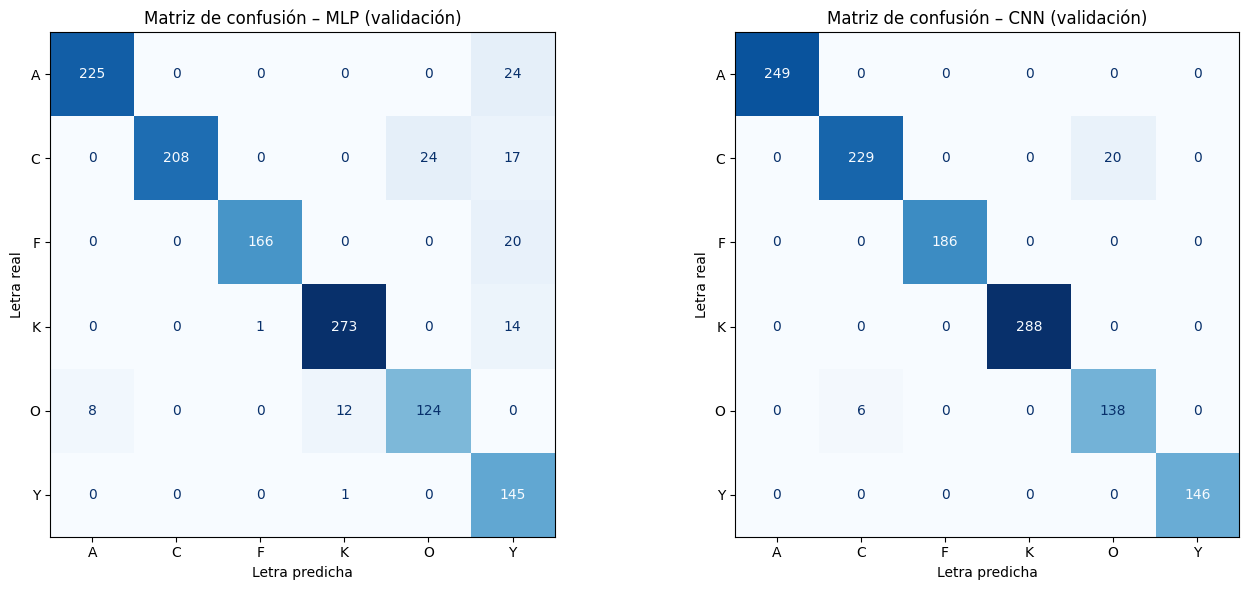

MLP: 121 errores de 1,262 imágenes. Principales confusiones: C → O (24), A → Y (24), F → Y (20), C → Y (17)
CNN: 26 errores de 1,262 imágenes. Principales confusiones: C → O (20), O → C (6)


In [ ]:
MATRICES = {tipo: confusion_matrix(Y_VAL, Y_PRED[tipo], labels=np.arange(N_CLASES)) for tipo in TIPOS}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, tipo in zip(axes, TIPOS):
    ConfusionMatrixDisplay(confusion_matrix=MATRICES[tipo], display_labels=LETRAS).plot(
        cmap="Blues", ax=ax, values_format="d", colorbar=False)
    ax.set_title(f"Matriz de confusión – {tipo} (validación)")
    ax.set_xlabel("Letra predicha"); ax.set_ylabel("Letra real"); ax.grid(False)
plt.tight_layout(); plt.show()


def principales_confusiones(cm: np.ndarray, letras: list, k: int = 4) -> list:
    """Devuelve los k pares (real -> predicha) con más errores."""
    fuera = cm.copy(); np.fill_diagonal(fuera, 0)
    orden = np.dstack(np.unravel_index(np.argsort(fuera, axis=None)[::-1], fuera.shape))[0]
    return [(letras[i], letras[j], int(fuera[i, j])) for i, j in orden[:k] if fuera[i, j] > 0]


for tipo in TIPOS:
    cm = MATRICES[tipo]
    errores = int(cm.sum() - np.trace(cm))
    pares = principales_confusiones(cm, LETRAS)
    detalle = ", ".join(f"{r} → {p} ({n})" for r, p, n in pares) if pares else "ninguna"
    print(f"{tipo}: {errores} errores de {cm.sum():,} imágenes. Principales confusiones: {detalle}")

### Lectura de las matrices de confusión
* **MLP: 121 errores** en 1.262 imágenes. Casi dos tercios terminan en **Y** (75 de 121): A → Y (24), F → Y (20), C → Y (17) y K → Y (14). Además confunde C → O (24) y O → K (12). La Y tiene Recall 0,99 pero Precision 0,66: la MLP la usa como "letra por defecto" cuando duda.
* **CNN: 26 errores**, solo entre las dos letras curvas: **C → O (20)** y **O → C (6)**. A, F, K e Y se reconocen al 100 %.
* La confusión C/O era esperable (ambas son manos curvas). Las confusiones de la MLP hacia la Y, en cambio, no se explican por parecido visual: indican que la MLP no capta bien la forma de la mano.

## 8.3 Curvas de aprendizaje de los modelos finales
Las curvas de entrenamiento vs validación están en la sección 5. Como la validación tiene fotos que el modelo no vio, la separación entre ambas curvas muestra directamente cuánto generaliza cada modelo.
* **MLP:** desde la época 9 el accuracy de validación se estanca en ≈ 90 % mientras el de entrenamiento sigue subiendo: sobreajuste (brecha 0,096).
* **CNN:** ambas curvas quedan juntas (≈ 97–99 %) y la pérdida de validación baja hasta el final: generaliza bien (brecha 0,020).

## 8.4 Análisis de sesgos
El dataset **no incluye metadatos** de las personas que realizaron las señas (edad, tono de piel, tamaño de la mano, iluminación, fondo), por lo que **no es posible medir equidad por grupos demográficos**. Con el conjunto de validación sí se puede auditar:

1. **Composición** de la validación (imágenes y fotos originales por letra).
2. **Desempeño desigual entre letras** (Precision, Recall y F1 por letra, tabla siguiente).
3. **Hacia qué letra se van los errores** (si el modelo "prefiere" alguna letra cuando se equivoca).
4. **Errores por foto original:** si los errores se concentran en pocas familias (fotos difíciles) o se reparten.
5. **Confianza de las predicciones**: si los errores ocurren con alta seguridad y cuántos se podrían derivar a revisión humana con un umbral de confianza.

In [ ]:
filas = []
for tipo in TIPOS:
    p, r, f, s = precision_recall_fscore_support(Y_VAL, Y_PRED[tipo], labels=np.arange(N_CLASES), zero_division=0)
    for i, letra in enumerate(LETRAS):
        filas.append({"Modelo": tipo, "Letra": letra, "Precision": p[i], "Recall": r[i], "F1": f[i], "Imágenes": int(s[i])})
TABLA_LETRAS = pd.DataFrame(filas)
display(TABLA_LETRAS.pivot(index="Letra", columns="Modelo", values=["Precision", "Recall", "F1"]).round(3))

Precision        Recall            F1       
Modelo       CNN    MLP    CNN    MLP    CNN    MLP
Letra                                              
A          1.000  0.966  1.000  0.904  1.000  0.934
C          0.974  1.000  0.920  0.835  0.946  0.910
F          1.000  0.994  1.000  0.892  1.000  0.941
K          1.000  0.955  1.000  0.948  1.000  0.951
O          0.873  0.838  0.958  0.861  0.914  0.849
Y          1.000  0.659  1.000  0.993  1.000  0.792

1) Composición de la validación
   A: 249 imágenes / 8 fotos, C: 249 imágenes / 8 fotos, F: 186 imágenes / 7 fotos, K: 288 imágenes / 13 fotos, O: 144 imágenes / 7 fotos, Y: 146 imágenes / 7 fotos
   Razón entre la letra más y menos frecuente = 2.00

2) Desempeño desigual entre letras (F1 en validación)
   MLP: F1 por letra entre 0.79 (Y) y 0.95 (K) | diferencia = 0.16
   CNN: F1 por letra entre 0.91 (O) y 1.00 (A) | diferencia = 0.09

3) ¿Hacia qué letra se van los errores?
   MLP: 121 errores. Letra predicha con más frecuencia al equivocarse: Y (75 de 121, 62 %)
   CNN: 26 errores. Letra predicha con más frecuencia al equivocarse: O (20 de 26, 77 %)

4) Errores por foto original (familia)
   MLP: los 121 errores vienen de 8 de las 50 fotos de validación; las 3 fotos con más errores concentran 65 (54 %)
   CNN: los 26 errores vienen de 2 de las 50 fotos de validación; las 3 fotos con más errores concentran 26 (100 %)

5) Confianza (probabilidad máxima) y umbral de revisión humana = 0.

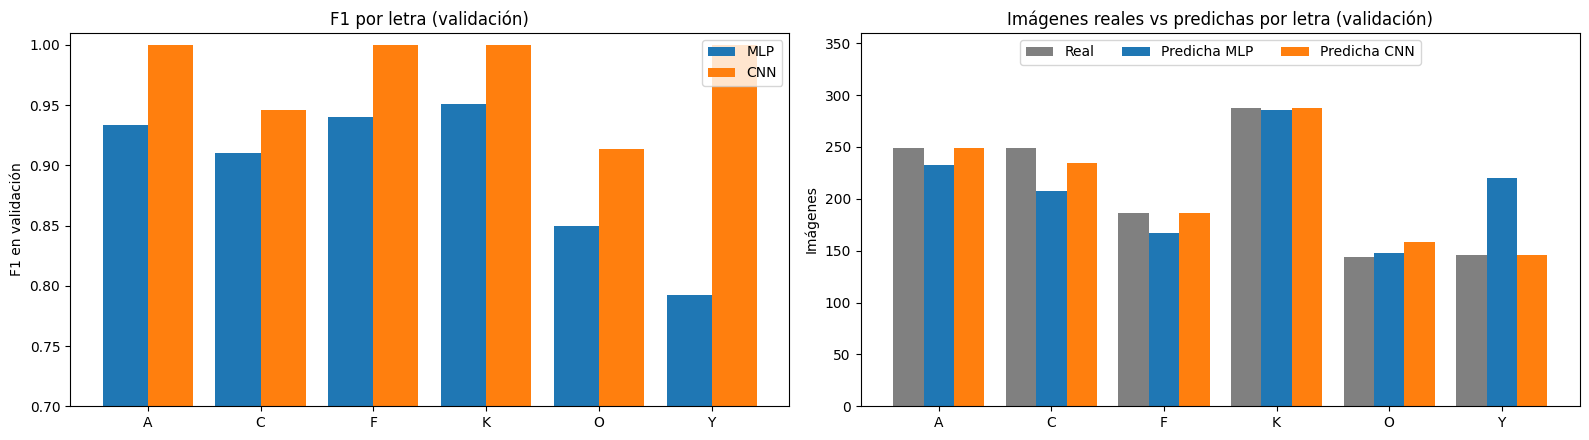

In [ ]:
def auditar_sesgos(datos: dict, y_pred: dict, proba: dict, f1_clases: dict, umbral: float = UMBRAL_CONFIANZA) -> None:
    """Audita sesgos con la validación: composición, desempeño por letra, destino de los errores, errores por familia y confianza."""
    y_true, g, letras = datos["y_val"], datos["g_val"], datos["letras"]
    n = len(letras)
    ce = np.bincount(y_true, minlength=n)
    fam = [len(np.unique(g[y_true == i])) for i in range(n)]
    print("1) Composición de la validación")
    print("   " + ", ".join(f"{l}: {c} imágenes / {f} fotos" for l, c, f in zip(letras, ce, fam)))
    print(f"   Razón entre la letra más y menos frecuente = {ce.max() / ce.min():.2f}")

    print("\n2) Desempeño desigual entre letras (F1 en validación)")
    for tipo in TIPOS:
        f = f1_clases[tipo]
        print(f"   {tipo}: F1 por letra entre {f.min():.2f} ({letras[f.argmin()]}) y {f.max():.2f} ({letras[f.argmax()]}) "
              f"| diferencia = {f.max() - f.min():.2f}")

    print("\n3) ¿Hacia qué letra se van los errores?")
    for tipo in TIPOS:
        err = y_pred[tipo] != y_true
        if not err.any():
            print(f"   {tipo}: sin errores"); continue
        destino = np.bincount(y_pred[tipo][err], minlength=n)
        print(f"   {tipo}: {err.sum()} errores. Letra predicha con más frecuencia al equivocarse: "
              f"{letras[destino.argmax()]} ({destino.max()} de {err.sum()}, {100 * destino.max() / err.sum():.0f} %)")

    print("\n4) Errores por foto original (familia)")
    for tipo in TIPOS:
        err = y_pred[tipo] != y_true
        if not err.any():
            print(f"   {tipo}: sin errores"); continue
        fam_err, cuenta = np.unique(g[err], return_counts=True)
        top = np.sort(cuenta)[::-1][:3]
        print(f"   {tipo}: los {err.sum()} errores vienen de {len(fam_err)} de las {len(np.unique(g))} fotos de validación; "
              f"las 3 fotos con más errores concentran {top.sum()} ({100 * top.sum() / err.sum():.0f} %)")

    print(f"\n5) Confianza (probabilidad máxima) y umbral de revisión humana = {umbral}")
    for tipo in TIPOS:
        conf = proba[tipo].max(axis=1); ok = y_pred[tipo] == y_true
        texto = f"   {tipo}: confianza media en aciertos = {conf[ok].mean():.3f}"
        if (~ok).any():
            texto += (f" | en errores = {conf[~ok].mean():.3f} | errores con confianza > {umbral}: "
                      f"{int(np.sum(conf[~ok] > umbral))} de {int(np.sum(~ok))}")
        print(texto)
        revision = conf < umbral
        print(f"        Con el umbral se derivarían a revisión humana {revision.sum()} imágenes "
              f"({100 * revision.mean():.1f} %), que contienen {int(np.sum(revision & ~ok))} de los {int(np.sum(~ok))} errores.")

    fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
    x = np.arange(n)
    for i, tipo in enumerate(TIPOS):
        axes[0].bar(x + (i - 0.5) * 0.4, f1_clases[tipo], 0.4, label=tipo)
    axes[0].set_xticks(x); axes[0].set_xticklabels(letras); axes[0].set_ylabel("F1 en validación")
    axes[0].set_ylim(max(0, min(0.7, min(f.min() for f in f1_clases.values()) - 0.05)), 1.01)
    axes[0].set_title("F1 por letra (validación)"); axes[0].legend()
    axes[1].bar(x - 0.27, ce, 0.27, label="Real", color="gray")
    for i, tipo in enumerate(TIPOS):
        axes[1].bar(x + i * 0.27, np.bincount(y_pred[tipo], minlength=n), 0.27, label=f"Predicha {tipo}")
    axes[1].set_xticks(x); axes[1].set_xticklabels(letras); axes[1].set_ylabel("Imágenes")
    axes[1].set_ylim(0, 1.25 * max(ce.max(), *(np.bincount(y_pred[t], minlength=n).max() for t in TIPOS)))
    axes[1].set_title("Imágenes reales vs predichas por letra (validación)"); axes[1].legend(ncol=3, loc="upper center")
    plt.tight_layout(); plt.show()


auditar_sesgos(datos, Y_PRED, PROBA, F1_CLASES)

### Sesgos identificados e implicancias
* **Sesgo de cobertura:** el modelo reconoce solo **6 de las 26 letras** (A, C, F, K, O, Y). Cualquier otra seña será clasificada a la fuerza como una de estas 6, porque la capa softmax siempre elige una. Si se desplegara como herramienta de accesibilidad, un usuario podría creer que "entiende" señas que en realidad no conoce.
* **Sesgo de representación (desconocido):** al no haber metadatos, no se puede verificar que el conjunto incluya variedad de personas, manos, iluminación y fondos. Un modelo entrenado con pocas personas tiende a funcionar peor con personas distintas, y ese error recaería sobre grupos subrepresentados.
* **Pocas fotos y validación desbalanceada:** la validación tiene 50 fotos originales, entre 7 (F, O, Y) y 13 (K) por letra, y la razón entre la letra con más y menos imágenes es **2,0** (K: 288 vs O: 144). Por eso se reportan métricas macro y por letra, y el resultado depende de qué fotos quedaron en cada lado de la partición.
* **Errores concentrados por foto:** los 121 errores de la MLP vienen de solo **8 de las 50 fotos** (las 3 peores concentran el 54 %) y los 26 de la CNN de solo **2 fotos**. Cuando un modelo falla con una foto, falla con muchas de sus variaciones: el riesgo está en ciertas fotos (persona, encuadre, iluminación), no en imágenes sueltas.
* **Desempeño desigual y destino de los errores:** la MLP va de F1 0,79 (Y) a 0,95 (K) y el **62 % de sus errores termina en Y**; la CNN va de 0,91 (O) a 1,00 y el 77 % de sus errores termina en O. En un uso real, estas preferencias perjudicarían siempre a las mismas señas.
* **Confianza:** ningún error de la MLP supera 0,9 de confianza, pero un umbral de 0,9 derivaría a revisión el 69,7 % de las imágenes: impracticable. En la CNN, **9 de sus 26 errores tienen confianza mayor a 0,9** (errores "seguros", que ningún umbral filtra); con umbral 0,9 se derivaría solo el 3,8 % de las imágenes y se capturarían 17 de los 26 errores.
* **Dificultad del subconjunto:** las 6 letras elegidas son visualmente distintas, por lo que el problema es mucho más fácil que el alfabeto completo. Los resultados **no se pueden extrapolar** a las 24 letras, donde hay pares muy parecidos (M/N, U/V, R/U).
* **Implicancia ética:** los datos son imágenes de personas. En un uso real se requiere **consentimiento informado**, resguardo de la privacidad y evitar decisiones automáticas de alto impacto sin supervisión humana.

### Medidas de mitigación propuestas
1. **Ampliar y diversificar el dataset:** más personas y más fotos originales por letra, con distintos tonos de piel, tamaños de mano, fondos e iluminación, y con metadatos para poder auditar por grupo.
2. **Balancear o ponderar clases** (`class_weight`) y reportar métricas por letra, no solo globales.
3. **Data Augmentation más variado:** cambios de brillo y contraste, además de los geométricos ya usados.
4. **Validación por persona:** separar entrenamiento y validación por individuo (como aquí por foto) para medir la generalización a personas nuevas.
5. **Umbral de confianza:** no emitir predicción si la probabilidad máxima es baja y derivar a revisión humana. Es clave aquí, porque cualquier seña fuera de las 6 letras se forzaría a una de ellas.
6. **Comunicar limitaciones:** indicar explícitamente que solo se reconocen 6 letras y publicar las métricas por letra.

## 8.5 IA Explicable (XAI): Grad-CAM
**Grad-CAM** (*Gradient-weighted Class Activation Mapping*) muestra **qué zonas de la imagen influyeron en la predicción de una CNN**. Funciona así: toma los mapas de activación de la última capa convolucional, pondera cada uno por el gradiente del puntaje de la clase (logit, antes de softmax) respecto de ese mapa, los suma y aplica ReLU. El resultado es un mapa de calor (zonas rojas = mayor influencia) que se superpone a la imagen.

Grad-CAM **solo es aplicable a la CNN**, porque necesita mapas convolucionales. Para la MLP, la alternativa es un **mapa de saliencia por gradiente** (función `calcular_saliencia`: gradiente de la probabilidad de la clase respecto de cada píxel), que no entrega regiones espaciales comparables.

Se explican imágenes de **validación**: tres acertadas por ambos modelos y hasta tres mal clasificadas por al menos uno.

**Cómo leer los mapas:** una explicación confiable se concentra en la **mano** (forma de los dedos y contorno). Si el calor se ubicara en el fondo o en los bordes de la imagen, el modelo estaría aprendiendo atajos que no generalizan.

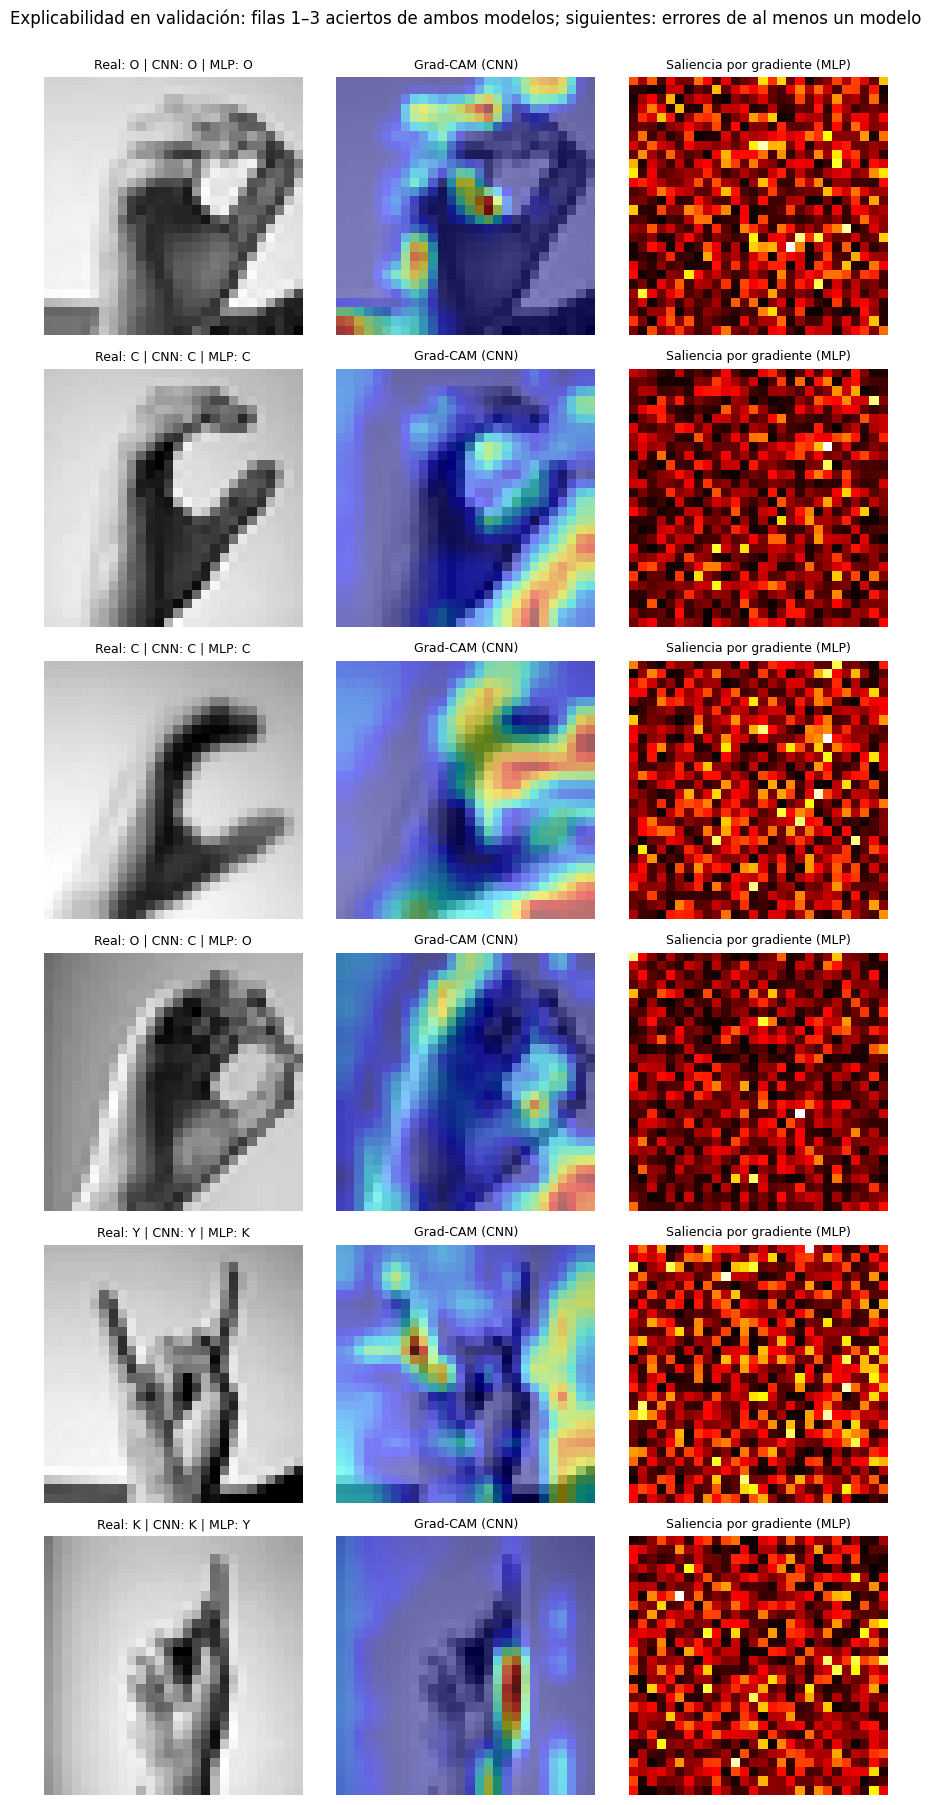

In [ ]:
def ultima_capa_conv(modelo) -> str:
    """Nombre de la última capa de activación convolucional (ReLU) del modelo."""
    return [l.name for l in modelo.layers if l.name.startswith("conv_") and l.name.endswith("_relu")][-1]


def calcular_gradcam(modelo, imagen: np.ndarray):
    """
    Calcula el mapa Grad-CAM (sobre el logit) de la clase predicha para una imagen (28, 28, 1).

    Returns:
        (mapa de calor 28x28 normalizado en [0, 1], índice de la clase predicha)
    """
    capa = modelo.get_layer(ultima_capa_conv(modelo))
    capa_salida = modelo.get_layer("salida")
    grad_model = keras.Model(modelo.inputs, [capa.output, capa_salida.input])
    x = tf.convert_to_tensor(imagen[np.newaxis, ...])
    with tf.GradientTape() as tape:
        mapas, caracteristicas = grad_model(x, training=False)
        logits = tf.matmul(caracteristicas, capa_salida.kernel) + capa_salida.bias
        clase = int(tf.argmax(logits[0]))
        puntaje = logits[:, clase]      # se usa el logit (antes de softmax) para evitar saturación
    grads = tape.gradient(puntaje, mapas)
    pesos = tf.reduce_mean(grads, axis=(1, 2))                       # importancia de cada filtro
    cam = tf.reduce_sum(mapas * pesos[:, tf.newaxis, tf.newaxis, :], axis=-1)[0]
    cam = tf.nn.relu(cam)
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., tf.newaxis], (28, 28)).numpy()[..., 0]
    return cam, clase


def calcular_saliencia(modelo, imagen: np.ndarray) -> np.ndarray:
    """Mapa de saliencia por gradiente (|d prob_clase / d píxel|), normalizado en [0, 1]."""
    x = tf.convert_to_tensor(imagen[np.newaxis, ...])
    with tf.GradientTape() as tape:
        tape.watch(x)
        preds = modelo(x, training=False)
        puntaje = preds[:, int(tf.argmax(preds[0]))]
    g = tf.abs(tape.gradient(puntaje, x))[0, :, :, 0]
    return (g / (tf.reduce_max(g) + 1e-8)).numpy()


def mostrar_explicaciones(datos: dict, modelos: dict, y_pred: dict, n_ok: int = 3, n_error: int = 3) -> None:
    """
    Muestra, para imágenes de VALIDACIÓN acertadas por ambos modelos y mal clasificadas por alguno:
    imagen original | Grad-CAM de la CNN | saliencia de la MLP.
    """
    rng = np.random.default_rng(SEMILLA)
    y = datos["y_val"]
    ok = np.where((y_pred["CNN"] == y) & (y_pred["MLP"] == y))[0]
    mal = np.where((y_pred["CNN"] != y) | (y_pred["MLP"] != y))[0]
    idx = list(rng.choice(ok, min(n_ok, len(ok)), replace=False))
    if len(mal) > 0:
        idx += list(rng.choice(mal, min(n_error, len(mal)), replace=False))
    letras = datos["letras"]
    fig, axes = plt.subplots(len(idx), 3, figsize=(9, 3 * len(idx)), squeeze=False)
    for fila, i in enumerate(idx):
        img = datos["X_val"][i]
        cam, _ = calcular_gradcam(modelos["CNN"]["modelo"], img)

        real = letras[y[i]]
        axes[fila, 0].imshow(img[..., 0], cmap="gray")
        axes[fila, 0].set_title(f"Real: {real} | CNN: {letras[y_pred['CNN'][i]]} | MLP: {letras[y_pred['MLP'][i]]}", fontsize=9)
        axes[fila, 1].imshow(img[..., 0], cmap="gray"); axes[fila, 1].imshow(cam, cmap="jet", alpha=0.5)
        axes[fila, 1].set_title("Grad-CAM (CNN)", fontsize=9)

        for ax in axes[fila]:
            ax.axis("off")
    plt.suptitle(f"Explicabilidad en validación: filas 1–{min(n_ok, len(ok))} aciertos de ambos modelos; "
                 "siguientes: errores de al menos un modelo", y=1.0)
    plt.tight_layout(); plt.show()


mostrar_explicaciones(datos, MODELOS, Y_PRED)

### Interpretación de las explicaciones
Con padding `valid`, el último mapa convolucional es de 11×11, así que el mapa Grad-CAM tiene baja resolución y marca regiones amplias.
* **Aciertos de ambos modelos (O, C, C):** en la O, la atención de la CNN cae en la parte superior del círculo que forman los dedos, pero también en el borde izquierdo y la esquina inferior izquierda de la imagen (fondo). En las dos C, sobre la curva interior de la mano y, en parte, sobre la muñeca y el borde inferior derecho.
* **O clasificada como C por la CNN:** la atención se reparte por el contorno izquierdo de la mano y apenas toca el círculo de los dedos; vista así, la mano curva se parece a una C. Es la confusión C/O de la matriz.
* **Errores de la MLP que la CNN acierta (Y → K y K → Y):** en la Y, la CNN mira los dedos extendidos (pulgar y meñique) y también una franja en el borde derecho; en la K, una franja vertical sobre el contorno de los dedos extendidos.
* **Hallazgo de auditoría:** la CNN se apoya principalmente en la forma de los dedos y el contorno de la mano, pero en varios casos también usa el fondo, la muñeca o los bordes de la imagen (posibles atajos que no existirían con otras cámaras y fondos). Medidas: centrar y recortar la mano antes de clasificar, aumentar los datos con cambios de fondo y encuadre, y revisar con Grad-CAM una muestra mayor.
* **MLP:** al no tener mapas convolucionales no admite Grad-CAM; su saliencia por gradiente se reparte por toda la imagen como ruido, por lo que la MLP es mucho más difícil de auditar.
* **Uso para respaldar decisiones:** la explicabilidad permite auditar *por qué* el modelo decide y detectar atajos antes de un despliegue; es un criterio adicional (no solo la métrica) para recomendar un modelo.

# 9. Optimización de hiperparámetros

**Etapa 9 del pipeline (optimización).** Se usa **búsqueda en grilla (*grid search*)**: se entrena cada combinación de valores de los hiperparámetros, se evalúa en validación y se elige la configuración con mejor desempeño.

| Elemento | Decisión |
|---|---|
| Punto de partida | Configuración de la sección 5 (regularización integrada). Esa combinación está en la grilla y se reutiliza sin reentrenar |
| Hiperparámetros buscados | MLP: tasa de aprendizaje y Dropout. CNN: tasa de aprendizaje, Dropout y L2 |
| Fijos | Arquitectura (sección 4), tamaño de lote (128), épocas máximas (15), Batch Normalization, Data Augmentation y Early Stopping en la CNN |
| Criterio de selección | **F1-macro en validación** (desempate: menor pérdida de validación). Se usa F1 y no solo accuracy porque pondera por igual todas las letras |
| Experimentos controlados | Toda la grilla se entrena con los mismos datos, semilla y condiciones; además se muestra el efecto de **cambiar un hiperparámetro a la vez** desde la mejor configuración |

| Hiperparámetro | Valores evaluados | Combinaciones |
|---|---|---|
| `lr` (tasa de aprendizaje) | 0,01 · 0,001 · 0,0001 | — |
| `dropout` | 0,0 · 0,3 · 0,5 | — |
| `l2` (solo CNN) | 0 · 0,0001 · 0,001 | — |
| **Total** | | **MLP: 3 × 3 = 9 · CNN: 3 × 3 × 3 = 27** |

Incluir Dropout = 0 y L2 = 0 permite medir el aporte de esas técnicas de regularización (sección 6).

In [ ]:
GRILLA = {"lr": [1e-2, 1e-3, 1e-4], "dropout": [0.0, 0.3, 0.5], "l2": [0.0, 1e-4, 1e-3]}
HIPERPARAMETROS = {"MLP": ["lr", "dropout"],          # la MLP no usa L2
                   "CNN": ["lr", "dropout", "l2"]}
RESULTADOS_GRILLA = {}   # (tipo, valores) -> resultado entrenado


def evaluar_configuracion(cfg: dict, datos: dict) -> dict:
    """
    Entrena la configuración y la evalúa en validación. Si es la configuración de la sección 5,
    reutiliza ese modelo en vez de entrenarlo otra vez.
    """
    tipo = cfg["modelo"]
    res = MODELOS[tipo] if cfg == CFG[tipo] else entrenar(cfg, datos)
    proba = res["modelo"].predict(datos["X_val"], batch_size=512, verbose=0)
    return {**res, "metricas_val": calcular_metricas(datos["y_val"], proba), "reutilizado": cfg == CFG[tipo]}


def grid_search(tipo: str, datos: dict):
    """
    Búsqueda en grilla: entrena todas las combinaciones de los hiperparámetros del modelo.

    Criterio: mayor F1-macro de validación (desempate: menor val_loss).

    Returns:
        (mejor resultado, tabla con todas las combinaciones)
    """
    hps = HIPERPARAMETROS[tipo]
    filas = []
    for valores in itertools.product(*(GRILLA[h] for h in hps)):
        cfg = {**CFG[tipo], **dict(zip(hps, valores))}
        r = evaluar_configuracion(cfg, datos)
        RESULTADOS_GRILLA[(tipo, valores)] = r
        m = r["metricas_val"]
        filas.append({**dict(zip(hps, valores)), "Val acc": m["accuracy"], "Val F1": m["f1"], "Val loss": r["val_loss"],
                      "Épocas": r["epocas_ejecutadas"], "Tiempo (s)": r["tiempo"]})
        print(f"[{tipo}] " + ", ".join(f"{h}={v}" for h, v in zip(hps, valores)) +
              f" -> F1 val {m['f1']:.4f} | acc {m['accuracy']:.4f} | val_loss {r['val_loss']:.4f}"
              + (" (modelo de la sección 5)" if r["reutilizado"] else f" | {r['tiempo']:.0f} s"))
    tabla = pd.DataFrame(filas)
    i_mejor = max(range(len(tabla)), key=lambda i: (tabla.loc[i, "Val F1"], -tabla.loc[i, "Val loss"]))
    mejor = RESULTADOS_GRILLA[(tipo, tuple(tabla.loc[i_mejor, h] for h in hps))]
    return mejor, tabla


def un_hiperparametro_a_la_vez(tabla: pd.DataFrame, tipo: str, mejor_cfg: dict) -> pd.DataFrame:
    """Desde la mejor configuración, muestra el efecto de cambiar un solo hiperparámetro (filas de la grilla)."""
    hps = HIPERPARAMETROS[tipo]
    filas = []
    for h in hps:
        otros = [o for o in hps if o != h]
        sub = tabla[np.logical_and.reduce([tabla[o] == mejor_cfg[o] for o in otros])] if otros else tabla
        for _, f in sub.sort_values(h).iterrows():
            filas.append({"Hiperparámetro variado": h, "Valor": f[h], "Val F1": f["Val F1"], "Val loss": f["Val loss"],
                          "Elegido": "✔" if f[h] == mejor_cfg[h] else ""})
    return pd.DataFrame(filas)


def graficar_grilla(tabla: pd.DataFrame, tipo: str, mejor_cfg: dict) -> None:
    """Mapa de calor del F1 de validación: tasa de aprendizaje × Dropout (en la CNN, con el mejor L2)."""
    sub = tabla[tabla["l2"] == mejor_cfg["l2"]] if "l2" in tabla else tabla
    piv = sub.pivot(index="lr", columns="dropout", values="Val F1").sort_index(ascending=False)
    fig, ax = plt.subplots(figsize=(5.5, 4))
    im = ax.imshow(piv.values, cmap="viridis", vmin=max(0, tabla["Val F1"].min()), vmax=1)
    ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns)
    ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels(piv.index)
    ax.set_xlabel("Dropout"); ax.set_ylabel("Tasa de aprendizaje")
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            v = piv.values[i, j]
            ax.text(j, i, f"{v:.3f}", ha="center", va="center", color="white" if v < 0.85 else "black", fontsize=10)
    extra = f" (L2 = {mejor_cfg['l2']})" if "l2" in tabla else ""
    ax.set_title(f"F1 de validación – {tipo}{extra}"); fig.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout(); plt.show()


MEJORES, TABLAS_GRILLA = {}, {}
t0 = time.perf_counter()
for tipo in TIPOS:
    print(f"\n########## Grid search: {tipo} ##########")
    MEJORES[tipo], TABLAS_GRILLA[tipo] = grid_search(tipo, datos)
print(f"\nTiempo total del grid search: {time.perf_counter() - t0:.0f} s")


########## Grid search: MLP ##########
[MLP] lr=0.01, dropout=0.0 -> F1 val 0.9206 | acc 0.9247 | val_loss 0.3063 | 6 s
[MLP] lr=0.01, dropout=0.3 -> F1 val 0.4044 | acc 0.5182 | val_loss 5.7663 | 9 s
[MLP] lr=0.01, dropout=0.5 -> F1 val 0.6101 | acc 0.6751 | val_loss 1.9287 | 9 s
[MLP] lr=0.001, dropout=0.0 -> F1 val 0.9232 | acc 0.9263 | val_loss 0.2100 | 7 s
[MLP] lr=0.001, dropout=0.3 -> F1 val 0.8941 | acc 0.9041 | val_loss 0.3191 | 9 s
[MLP] lr=0.001, dropout=0.5 -> F1 val 0.8773 | acc 0.8891 | val_loss 0.3354 | 9 s
[MLP] lr=0.0001, dropout=0.0 -> F1 val 0.8906 | acc 0.9033 | val_loss 0.3806 | 8 s
[MLP] lr=0.0001, dropout=0.3 -> F1 val 0.8962 | acc 0.9041 | val_loss 0.3880 (modelo de la sección 5)
[MLP] lr=0.0001, dropout=0.5 -> F1 val 0.8987 | acc 0.9097 | val_loss 0.4922 | 9 s

########## Grid search: CNN ##########
[CNN] lr=0.01, dropout=0.0, l2=0.0 -> F1 val 0.9761 | acc 0.9786 | val_loss 0.0809 | 8 s
[CNN] lr=0.01, dropout=0.0, l2=0.0001 -> F1 val 0.9824 | acc 0.9842 | val_


==================== MLP: resultados del grid search ====================


,lr,dropout,Val acc,Val F1,Val loss,Épocas,Tiempo (s)
0,0.0010,0.0,0.9263,0.9232,0.2100,15,6.8384
1,0.0100,0.0,0.9247,0.9206,0.3063,15,6.4970
2,0.0001,0.5,0.9097,0.8987,0.4922,15,9.0136
3,0.0001,0.3,0.9041,0.8962,0.3880,15,11.4079
4,0.0010,0.3,0.9041,0.8941,0.3191,15,8.5127
5,0.0001,0.0,0.9033,0.8906,0.3806,15,7.6789
6,0.0010,0.5,0.8891,0.8773,0.3354,15,9.3733
7,0.0100,0.5,0.6751,0.6101,1.9287,15,9.1269
8,0.0100,0.3,0.5182,0.4044,5.7663,15,9.0481


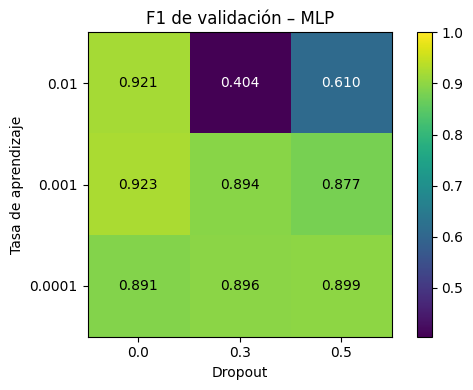

Efecto de cambiar un hiperparámetro a la vez desde la mejor configuración:


,Hiperparámetro variado,Valor,Val F1,Val loss,Elegido
0,lr,0.0001,0.8906,0.3806,
1,lr,0.0010,0.9232,0.2100,✔
2,lr,0.0100,0.9206,0.3063,
3,dropout,0.0000,0.9232,0.2100,✔
4,dropout,0.3000,0.8941,0.3191,
5,dropout,0.5000,0.8773,0.3354,


Mejor configuración MLP: lr=0.001, dropout=0.0 | F1 val 0.9232 (configuración de partida: 0.8962, +0.0270)

==================== CNN: resultados del grid search ====================


,lr,dropout,l2,Val acc,Val F1,Val loss,Épocas,Tiempo (s)
0,0.0100,0.3,0.0001,0.9834,0.9827,0.0911,15,13.1970
1,0.0100,0.0,0.0001,0.9842,0.9824,0.1523,15,10.8514
2,0.0010,0.0,0.0000,0.9842,0.9822,0.0609,14,10.1745
3,0.0010,0.0,0.0001,0.9842,0.9822,0.0802,14,10.0810
4,0.0010,0.3,0.0010,0.9794,0.9767,0.1856,15,15.8417
5,0.0100,0.0,0.0000,0.9786,0.9761,0.0809,10,7.8403
6,0.0010,0.0,0.0010,0.9786,0.9758,0.1669,15,10.7940
7,0.0100,0.5,0.0001,0.9778,0.9748,0.1347,10,8.9895
8,0.0010,0.5,0.0000,0.9746,0.9711,0.0549,14,11.3791
9,0.0010,0.3,0.0000,0.9746,0.9703,0.0534,15,9.9709


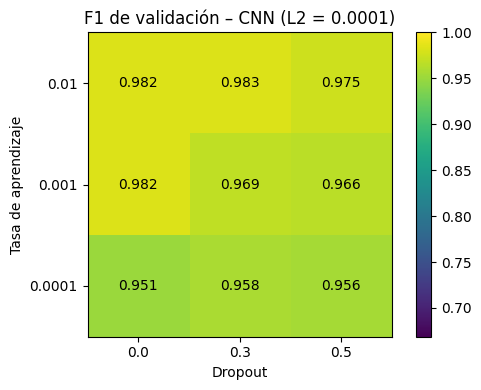

Efecto de cambiar un hiperparámetro a la vez desde la mejor configuración:


,Hiperparámetro variado,Valor,Val F1,Val loss,Elegido
0,lr,0.0001,0.9575,0.2053,
1,lr,0.0010,0.9686,0.0782,
2,lr,0.0100,0.9827,0.0911,✔
3,dropout,0.0000,0.9824,0.1523,
4,dropout,0.3000,0.9827,0.0911,✔
5,dropout,0.5000,0.9748,0.1347,
6,l2,0.0000,0.9655,0.1051,
7,l2,0.0001,0.9827,0.0911,✔
8,l2,0.0010,0.8335,0.8910,


Mejor configuración CNN: lr=0.01, dropout=0.3, l2=0.0001 | F1 val 0.9827 (configuración de partida: 0.9767, +0.0060)


In [ ]:
CFG_OPT = {tipo: MEJORES[tipo]["cfg"] for tipo in TIPOS}
for tipo in TIPOS:
    hps = HIPERPARAMETROS[tipo]
    print(f"\n==================== {tipo}: resultados del grid search ====================")
    display(TABLAS_GRILLA[tipo].sort_values(["Val F1", "Val loss"], ascending=[False, True]).round(4).reset_index(drop=True))
    graficar_grilla(TABLAS_GRILLA[tipo], tipo, CFG_OPT[tipo])
    print("Efecto de cambiar un hiperparámetro a la vez desde la mejor configuración:")
    display(un_hiperparametro_a_la_vez(TABLAS_GRILLA[tipo], tipo, CFG_OPT[tipo]).round(4))
    c, m0, m1 = CFG_OPT[tipo], METRICAS[tipo], MEJORES[tipo]["metricas_val"]
    print(f"Mejor configuración {tipo}: " + ", ".join(f"{h}={c[h]}" for h in hps) +
          f" | F1 val {m1['f1']:.4f} (configuración de partida: {m0['f1']:.4f}, {m1['f1'] - m0['f1']:+.4f})")

### Justificación de la configuración seleccionada
El *grid search* completo (36 configuraciones) tardó 343 s en GPU.

**MLP optimizada:** `lr = 0,001` y **sin Dropout** (Batch Normalization se mantiene) → F1 de validación **0,923** (partida: 0,896, +0,027).
* **Tasa de aprendizaje:** 0,0001 es demasiado lenta para 15 épocas (0,891) y 0,01 funciona sin Dropout (0,921), pero colapsa con Dropout 0,3 (0,404) y 0,5 (0,610).
* **Dropout:** con lr = 0,001, cada aumento de Dropout baja el F1 (0,923 → 0,894 → 0,877): en una MLP de solo 128 y 64 neuronas, Dropout le quita más capacidad de la que aporta como regularización.

**CNN optimizada:** `lr = 0,01`, `dropout = 0,3`, `l2 = 0,0001`, con Batch Normalization, Data Augmentation y Early Stopping → F1 de validación **0,983** (partida: 0,977, +0,006).
* **Tasa de aprendizaje:** con el resto en su mejor valor, 0,0001 es demasiado lenta (0,958), 0,001 da 0,969 y 0,01 da 0,983.
* **L2:** 0,0001 es el mejor; sin L2 baja a 0,966 y con 0,001 el modelo no aprende con lr = 0,01 (0,834).
* **Dropout:** 0,3 y 0 prácticamente empatan (0,983 y 0,982); 0,5 baja a 0,975.

**Diferencias pequeñas:** las cuatro mejores configuraciones de la CNN están entre 0,982 y 0,983 (una o dos imágenes de diferencia). Con 50 fotos de validación, diferencias menores a ≈ 0,01 no son significativas: cualquiera de ellas sería una buena elección.

**Limitación:** la validación se usa para elegir la configuración y también para comparar los modelos optimizados, por lo que sus métricas finales pueden ser levemente optimistas; con más datos convendría una validación cruzada por familias o un conjunto de prueba independiente.

# 10. Comparación objetiva MLP vs CNN
Se comparan los modelos **optimizados** (mejor configuración del *grid search*), con las métricas de validación, la brecha entrenamiento–validación, el tamaño del modelo y el tiempo de su entrenamiento.

,MLP,CNN
Accuracy,0.9263,0.9834
Precision,0.9269,0.9836
Recall,0.9248,0.9824
F1-score,0.9232,0.9827
ROC-AUC,0.9959,0.9999
Errores en validación,93,21
Letra más difícil (F1),F (0.89),F (0.96)
Brecha train-val,0.0737,0.0097
F1 configuración de partida,0.8962,0.9767
Parámetros,"109,702","56,790"


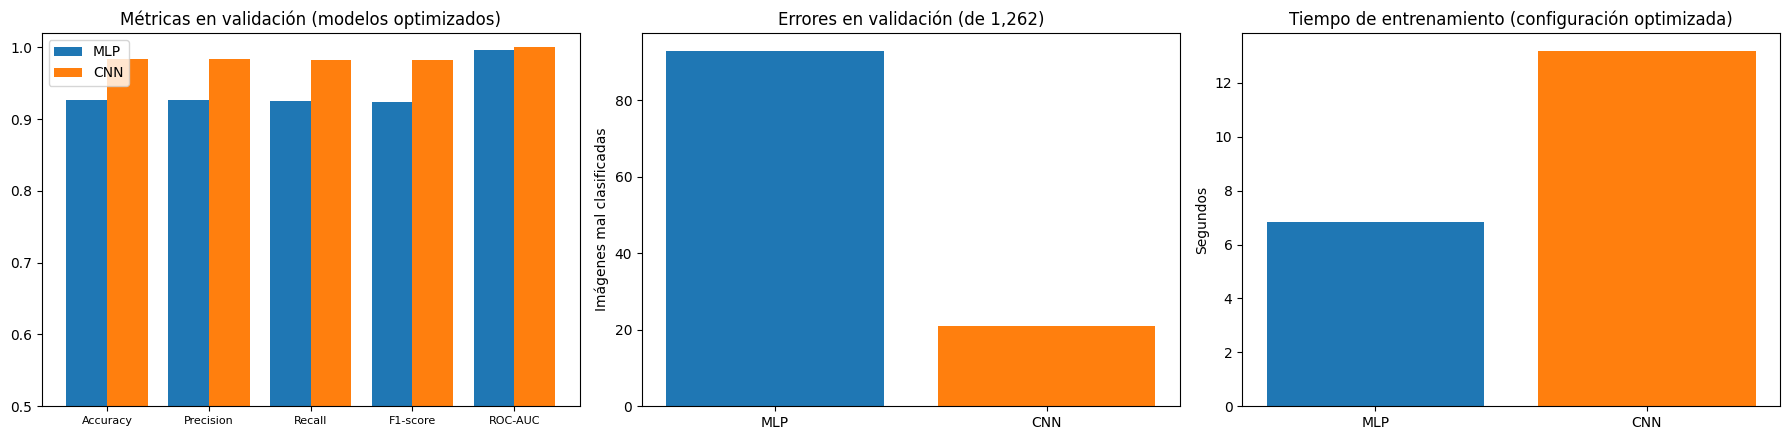

Modelo con mayor F1 en validación: CNN (0.9827), +0.0594 por encima de MLP (0.9232).
Errores en validación: CNN = 21 | MLP = 93.
Tiempo de entrenamiento: CNN tarda 1.9 veces el tiempo de MLP.


In [ ]:
def tabla_comparativa() -> pd.DataFrame:
    """Tabla con métricas de validación, brecha, errores, tamaño, tiempo e interpretabilidad de cada modelo optimizado."""
    interpretabilidad = {"MLP": "Saliencia por gradiente (pixel a pixel)",
                         "CNN": "Grad-CAM (mapas espaciales sobre la imagen)"}
    filas = {}
    for tipo in TIPOS:
        r = MEJORES[tipo]; m = r["metricas_val"]
        _, acc_train = r["modelo"].evaluate(datos["X_train"], datos["y_train"], batch_size=512, verbose=0)
        pred = r["modelo"].predict(datos["X_val"], batch_size=512, verbose=0).argmax(1)
        f1c = f1_por_clase(Y_VAL, pred)
        filas[tipo] = {**{NOMBRES_METRICAS[k]: m[k] for k in NOMBRES_METRICAS},
                       "Errores en validación": int((pred != Y_VAL).sum()),
                       "Letra más difícil (F1)": f"{LETRAS[f1c.argmin()]} ({f1c.min():.2f})",
                       "Brecha train-val": float(acc_train) - m["accuracy"],
                       "F1 configuración de partida": METRICAS[tipo]["f1"],
                       "Parámetros": r["params"], "Épocas entrenadas": r["epocas_ejecutadas"],
                       "Tiempo de entrenamiento (s)": r["tiempo"],
                       "Interpretabilidad": interpretabilidad[tipo]}
    return pd.DataFrame(filas)


def graficar_comparacion(tabla: pd.DataFrame) -> None:
    """Gráficos comparativos: métricas de validación, errores y tiempo de entrenamiento de los modelos optimizados."""
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    metricas = list(NOMBRES_METRICAS.values())
    x = np.arange(len(metricas))
    for i, tipo in enumerate(TIPOS):
        axes[0].bar(x + (i - 0.5) * 0.4, tabla.loc[metricas, tipo].astype(float), 0.4, label=tipo)
    axes[0].set_xticks(x); axes[0].set_xticklabels(metricas, fontsize=8)
    axes[0].set_ylim(0.5, 1.02); axes[0].set_title("Métricas en validación (modelos optimizados)"); axes[0].legend()
    axes[1].bar(TIPOS, [int(tabla.loc["Errores en validación", t]) for t in TIPOS], color=["tab:blue", "tab:orange"])
    axes[1].set_ylabel("Imágenes mal clasificadas"); axes[1].set_title(f"Errores en validación (de {len(Y_VAL):,})")
    axes[2].bar(TIPOS, [float(tabla.loc["Tiempo de entrenamiento (s)", t]) for t in TIPOS], color=["tab:blue", "tab:orange"])
    axes[2].set_ylabel("Segundos"); axes[2].set_title("Tiempo de entrenamiento (configuración optimizada)")
    plt.tight_layout(); plt.show()


TABLA_COMP = tabla_comparativa()
FORMATOS = {**{f: "{:.4f}" for f in list(NOMBRES_METRICAS.values()) + ["Brecha train-val", "F1 configuración de partida"]},
            "Tiempo de entrenamiento (s)": "{:.0f}", "Parámetros": "{:,.0f}"}
vista = TABLA_COMP.astype(object).copy()
for fila, fmt in FORMATOS.items():
    vista.loc[fila] = [fmt.format(float(v)) for v in TABLA_COMP.loc[fila]]
display(vista)
graficar_comparacion(TABLA_COMP)

GANADOR = max(TIPOS, key=lambda t: (MEJORES[t]["metricas_val"]["f1"], MEJORES[t]["metricas_val"]["accuracy"]))
PERDEDOR = [t for t in TIPOS if t != GANADOR][0]
mg, mp = MEJORES[GANADOR]["metricas_val"], MEJORES[PERDEDOR]["metricas_val"]
razon_t = MEJORES[GANADOR]["tiempo"] / MEJORES[PERDEDOR]["tiempo"]
print(f"Modelo con mayor F1 en validación: {GANADOR} ({mg['f1']:.4f}), {mg['f1'] - mp['f1']:+.4f} por encima de {PERDEDOR} ({mp['f1']:.4f}).")
print(f"Errores en validación: {GANADOR} = {int(TABLA_COMP.loc['Errores en validación', GANADOR])} | "
      f"{PERDEDOR} = {int(TABLA_COMP.loc['Errores en validación', PERDEDOR])}.")
print(f"Tiempo de entrenamiento: {GANADOR} tarda {razon_t:.1f} veces el tiempo de {PERDEDOR}.")

### Análisis comparativo y modelo recomendado
| Criterio | MLP optimizada | CNN optimizada | Mejor |
|---|---|---|---|
| F1 macro (validación) | 0,923 | **0,983** | CNN (+0,059) |
| Accuracy | 0,926 (93 errores de 1.262) | **0,983** (21 errores) | CNN |
| Precision / Recall (macro) | 0,927 / 0,925 | **0,984 / 0,982** | CNN |
| ROC-AUC | 0,996 | **0,9999** | CNN |
| Letra más difícil (F1) | F: 0,89 | F: 0,96 | CNN |
| Brecha entrenamiento–validación | 0,074 | **0,010** | CNN |
| Parámetros | 109.702 | **56.790** | CNN (≈ la mitad) |
| Tiempo de entrenamiento (GPU) | **7 s** | 13 s (1,9×) | MLP |
| Interpretabilidad | Sin mapas espaciales (saliencia ruidosa) | Grad-CAM | CNN |

*Los parámetros incluyen los de Batch Normalization; sin ellos son 109.126 (MLP) y 56.454 (CNN).*

1. **Desempeño predictivo:** la CNN comete 21 errores en 1.262 imágenes, frente a 93 de la MLP (4,4 veces menos), y su peor letra queda en F1 0,96.
2. **Generalización:** la brecha de la CNN es 0,010 y la de la MLP 0,074: aun optimizada, la MLP sigue sobreajustando a las fotos de entrenamiento.
3. **Interpretabilidad:** Grad-CAM muestra que la CNN se apoya principalmente en los dedos y el contorno de la mano, y permite detectar cuándo usa fondo, muñeca o bordes (sección 8.5). La MLP no admite Grad-CAM.
4. **Costo computacional:** la CNN tiene la mitad de parámetros, porque comparte los pesos de cada filtro en toda la imagen, pero tarda 1,9 veces más en entrenar (≈ 6 segundos más) por las convoluciones y el aumento de datos. La diferencia de costo es mínima.

Ambas cifras vienen de la misma validación que eligió la configuración; aun así, la diferencia entre los modelos (0,059 de F1) es mucho mayor que la que hay entre las mejores configuraciones de cada uno.

**Argumento técnico de fondo:** la MLP recibe los 784 píxeles completos (Flatten no borra valores), pero cada neurona los trata como variables independientes, sin saber cuáles son vecinos. Por eso le cuesta separar letras que difieren en detalles locales y termina usando la Y como letra por defecto. La CNN usa filtros locales con pesos compartidos que detectan bordes y formas sin importar su posición exacta, lo que se ajusta a la naturaleza de una imagen de una mano.

**Recomendación: CNN optimizada** (`lr = 0,01`, Dropout 0,3, L2 = 0,0001). Supera a la MLP en todas las métricas de validación, generaliza mejor, tiene la mitad de parámetros y es más explicable. Su costo de entrenamiento adicional es mínimo.

# 11. Conclusiones

In [ ]:
def mostrar_conclusiones() -> None:
    """Imprime un resumen de conclusiones construido a partir de los resultados en validación."""
    print("RESULTADOS PRINCIPALES (validación con familias no vistas)")
    for t in TIPOS:
        c, m, r = CFG_OPT[t], MEJORES[t]["metricas_val"], MEJORES[t]
        print(f"• {t} optimizada (lr={c['lr']}, lote={c['batch_size']}, dropout={c['dropout']}, l2={c['l2']}): "
              f"Accuracy {m['accuracy']:.4f} | F1 {m['f1']:.4f} | AUC {m['roc_auc']:.4f} | "
              f"{int(TABLA_COMP.loc['Errores en validación', t])} errores | {r['params']:,} parámetros | {r['tiempo']:.0f} s de entrenamiento")
    g, p = GANADOR, PERDEDOR
    mg, mp = MEJORES[g]["metricas_val"], MEJORES[p]["metricas_val"]
    print(f"\n• Modelo recomendado: {g}. Supera a {p} en F1 de validación por {mg['f1'] - mp['f1']:+.4f} "
          f"y en accuracy por {mg['accuracy'] - mp['accuracy']:+.4f}.")
    for t in TIPOS:
        print(f"• Grid search {t}: F1 de {METRICAS[t]['f1']:.4f} (partida) a {MEJORES[t]['metricas_val']['f1']:.4f} (optimizada).")
    for t in TIPOS:
        pares = principales_confusiones(MATRICES[t], LETRAS, k=2)
        if pares:
            print(f"• Principales confusiones de {t} (modelo de la sección 5): " + ", ".join(f"{a} → {b} ({n})" for a, b, n in pares))
    print("• Interpretabilidad: la CNN ofrece Grad-CAM; la MLP solo saliencia píxel a píxel.")


mostrar_conclusiones()

RESULTADOS PRINCIPALES (validación con familias no vistas)
• MLP optimizada (lr=0.001, lote=128, dropout=0.0, l2=0.0): Accuracy 0.9263 | F1 0.9232 | AUC 0.9959 | 93 errores | 109,702 parámetros | 7 s de entrenamiento
• CNN optimizada (lr=0.01, lote=128, dropout=0.3, l2=0.0001): Accuracy 0.9834 | F1 0.9827 | AUC 0.9999 | 21 errores | 56,790 parámetros | 13 s de entrenamiento

• Modelo recomendado: CNN. Supera a MLP en F1 de validación por +0.0594 y en accuracy por +0.0571.
• Grid search MLP: F1 de 0.8962 (partida) a 0.9232 (optimizada).
• Grid search CNN: F1 de 0.9767 (partida) a 0.9827 (optimizada).
• Principales confusiones de MLP (modelo de la sección 5): C → O (24), A → Y (24)
• Principales confusiones de CNN (modelo de la sección 5): C → O (20), O → C (6)
• Interpretabilidad: la CNN ofrece Grad-CAM; la MLP solo saliencia píxel a píxel.


## 11.1 Conclusiones generales
* Se construyó un **pipeline integrado y modular** con las nueve etapas en orden (carga → EDA → preprocesamiento → construcción → entrenamiento → regularización → evaluación → auditoría → optimización), donde MLP y CNN usan las mismas funciones, los mismos datos y el mismo tamaño de lote (128). Las arquitecturas son **fijas**: MLP 128-64-6 (E1) y CNN de dos bloques Conv2D de 16 y 32 filtros + Dense 64.
* **Partición por familias:** el dataset se generó con muchas variaciones de pocas fotos originales. Con una partición aleatoria, el 94,9 % de la validación tendría una casi-copia en entrenamiento; separando 80/20 por familias baja a 0,7 %, y la validación mide el desempeño con fotos nuevas.
* **Entrenamiento y regularización:** cada modelo se entrenó una sola vez con su regularización integrada. La MLP sobreajusta (brecha 0,096) y la CNN mucho menos (0,020). En el *grid search*, Dropout no ayudó a la MLP, un L2 pequeño sí ayudó a la CNN y un L2 fuerte con tasa alta impidió aprender.
* **Auditoría:** la MLP comete 121 errores, el 62 % hacia la Y, concentrados en 8 de las 50 fotos de validación; la CNN comete 26, solo entre C y O y en 2 fotos. Grad-CAM mostró que la CNN mira sobre todo los dedos y el contorno de la mano, aunque a veces usa el fondo, la muñeca o los bordes. Sesgos principales: cobertura de solo 6 letras, falta de metadatos, pocas fotos por letra y validación desbalanceada (2:1).
* **Optimización:** *grid search* de 36 configuraciones (343 s): la MLP pasa de F1 0,896 a 0,923 (lr = 0,001, sin Dropout) y la CNN de 0,977 a 0,983 (lr = 0,01, Dropout 0,3, L2 = 0,0001).
* **Modelo recomendado: CNN optimizada**, con F1 0,983, 21 errores en 1.262 imágenes, brecha 0,010, la mitad de parámetros que la MLP y explicable con Grad-CAM, a cambio de 6 segundos más de entrenamiento.

## 11.2 Evaluación crítica del pipeline
| Aspecto | Fortalezas | Limitaciones y riesgos | Mejoras para una siguiente iteración |
|---|---|---|---|
| Diseño | Modular, reutilizable, con semillas fijas y un registro que evita reentrenar | Las operaciones en GPU no son deterministas: al repetir el notebook los resultados pueden variar levemente | Repetir con varias semillas y reportar media y desviación |
| Datos y partición | Partición por familias: la validación casi no tiene casi-copias del entrenamiento (0,7 %) | Solo 50 fotos en validación (7 a 13 por letra) y desbalance 2:1; los errores se concentran en pocas fotos | Validación cruzada por familias (`StratifiedGroupKFold` con 5 pliegues) |
| Entrenamiento | Un solo entrenamiento por modelo en la etapa 5, mismas condiciones para ambos | La MLP sobreajusta (brecha 0,096 de partida y 0,074 optimizada) | Data Augmentation también para la MLP |
| Optimización | *Grid search* completo y controlado, con efecto de un hiperparámetro a la vez | La misma validación elige y compara; las mejores configuraciones de la CNN difieren en menos de 0,001 | Conjunto de prueba independiente o validación cruzada anidada |
| Auditoría | Matrices de confusión, métricas por letra, sesgos por foto, confianza y Grad-CAM | Sin metadatos no se puede medir equidad por grupos | Recolectar metadatos y auditar por grupo |
| Explicabilidad | Grad-CAM sobre la CNN | La CNN usa en parte fondo, muñeca o bordes; solo se revisó una muestra | Recortar/centrar la mano y cuantificar cuánta atención cae sobre la mano |
| Datos | Dataset limpio y balanceado | Solo 6 de 26 letras, sin metadatos de las personas, imágenes de 28×28 | Ampliar a más letras, más personas y condiciones de captura, mayor resolución |
| Despliegue | Modelo seleccionado con evidencia experimental | No evaluado con imágenes reales de cámara | Prueba piloto con usuarios reales y umbral de confianza con revisión humana |